# 📋 Задание 2. Линейная регрессия (LinReg) и дисперсионный анализ (ANOVA)

### **[2.1]** Выбор датасета
Выбрать в качестве `df0` один из датасетов из перечня:
- Iris
- Palmer Archipelago (Antarctica) penguin
- Wine Quality
- Любой другой датасет, в котором есть **как минимум три класса** и **как минимум четыре количественных (недискретных) признака**.

---

In [78]:
import kagglehub
from pathlib import Path
# Download latest version
path = kagglehub.dataset_download("uciml/iris")
path = Path(path, 'Iris.csv')

print("Path to dataset files:", path)

Path to dataset files: /home/fedosdan2/.cache/kagglehub/datasets/uciml/iris/versions/2/Iris.csv


In [79]:
import pandas as pd

df0 = pd.read_csv(path)

df0 = df0.drop(columns=['Id'])

rename_map = {
    "SepalLengthCm": "SL",
    "SepalWidthCm":  "SW",
    "PetalLengthCm": "PL",
    "PetalWidthCm":  "PW",
}
df0 = df0.rename(columns=rename_map)

target = df0.columns[-1]        
features = df0.columns[:-1]

df0[target] = df0[target].map({
    'Iris-setosa': 0,
    'Iris-versicolor': 1,
    'Iris-virginica': 2
})

print(list(features), target)
display(df0.head(5))

['SL', 'SW', 'PL', 'PW'] Species


,SL,SW,PL,PW,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Добввим датасету Nan значения чтобы было интересно

In [80]:
import numpy as np

def add_random_missing_values(df, features, percent=20):
    df_out = df.copy()
    n_rows, n_cols = len(df), len(features)
    n = int(n_rows * n_cols * percent / 100)

    if n:
        idx = np.random.choice(n_rows * n_cols, n, replace=False)
        for i in idx:
            df_out.iat[i // n_cols, df.columns.get_loc(features[i % n_cols])] = np.nan
    return df_out

df0 = add_random_missing_values(df0, features, percent=20)
display(df0.head(5))

,SL,SW,PL,PW,Species
0,5.1,NaN,1.4,0.2,0
1,4.9,NaN,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,NaN,0
4,5.0,3.6,NaN,0.2,0



### **[2.2]** Статистика по датасету
Вывести в табличной форме статистику по датасету как в [1.2].

---


In [81]:
# Размерность всего датасета (объекты и признаки) 
print(f'Размерность датасета: {df0.shape}\n')

# Тип каждого признака
print(f'Тип каждого признака: \n{df0.dtypes}\n')

# Количество классов и объектов в каждом из классов
counts = df0[target].value_counts().sort_index()
print('Количество классов:', df0[target].nunique())
print('Объектов в каждом классе:')
print(f'{counts}\n')

def describe_extended(series):
    n_nan = series.isna().sum()          # сколько NaN в столбце
    x = series.dropna().to_numpy(float)  # отбрасываем NaN до расчётов

    # Защита: если после dropna ничего не осталось
    if x.size == 0:
        return pd.Series({
            'n_obs': 0, 'n_nan': n_nan,
            'mean': np.nan, 'median': np.nan, 'std': np.nan, 'var': np.nan,
            'min': np.nan, 'max': np.nan, 'q1': np.nan, 'q3': np.nan, 'iqr': np.nan,
        })

    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1

    return pd.Series({
        'n_obs': x.size,        # число учтённых (не-NaN) значений
        'n_nan': n_nan,         # число пропущенных значений
        'mean': np.mean(x),
        'median': np.median(x),
        'std': np.std(x, ddof=1),
        'var': np.var(x, ddof=1),
        'min': np.min(x),
        'max': np.max(x),
        'q1': q1,
        'q3': q3,
        'iqr': iqr,
    })

stats_table = df0.drop(columns=[target]).apply(describe_extended)
print('Различные оценки выборки: ')
print(stats_table.T.round(3), '\n')

Размерность датасета: (150, 5)

Тип каждого признака: 
SL         float64
SW         float64
PL         float64
PW         float64
Species      int64
dtype: object

Количество классов: 3
Объектов в каждом классе:
Species
0    50
1    50
2    50
Name: count, dtype: int64

Различные оценки выборки: 
    n_obs  n_nan   mean  median    std    var  min  max   q1   q3  iqr
SL  120.0   30.0  5.811     5.7  0.832  0.691  4.3  7.9  5.1  6.4  1.3
SW  121.0   29.0  3.027     3.0  0.379  0.144  2.0  3.9  2.8  3.3  0.5
PL  115.0   35.0  3.722     4.4  1.766  3.118  1.0  6.9  1.6  5.1  3.5
PW  124.0   26.0  1.169     1.3  0.738  0.544  0.1  2.5  0.3  1.8  1.5 



In [82]:
# Число объектов с NaN по классам
print('Число объектов с NaN по классам: ')
print(df0.groupby(target).apply(lambda g: g.isna().any(axis=1).sum()))


# Число объектов с 0 по классам
print('\nЧисло объектов с 0 по классам: ')
features = [c for c in df0.columns if c != target]
print(df0.groupby(target)[features].apply(lambda g: (g == 0).any(axis=1).sum()))


Число объектов с NaN по классам: 
Species
0    30
1    26
2    34
dtype: int64

Число объектов с 0 по классам: 
Species
0    0
1    0
2    0
dtype: int64



### **[2.3]** UpSet-plot визуализация пропусков и повторов
Для всего датасета выполнить в форме UpSet plot:
- визуализацию **чисел объектов с пропущенными значениями** для каждого варианта группировки пропусков по признакам;
- визуализацию **чисел объектов с повторяющимися значениями**, равными друг другу внутри одного признака, для каждого варианта группировки повторов по признакам.

---


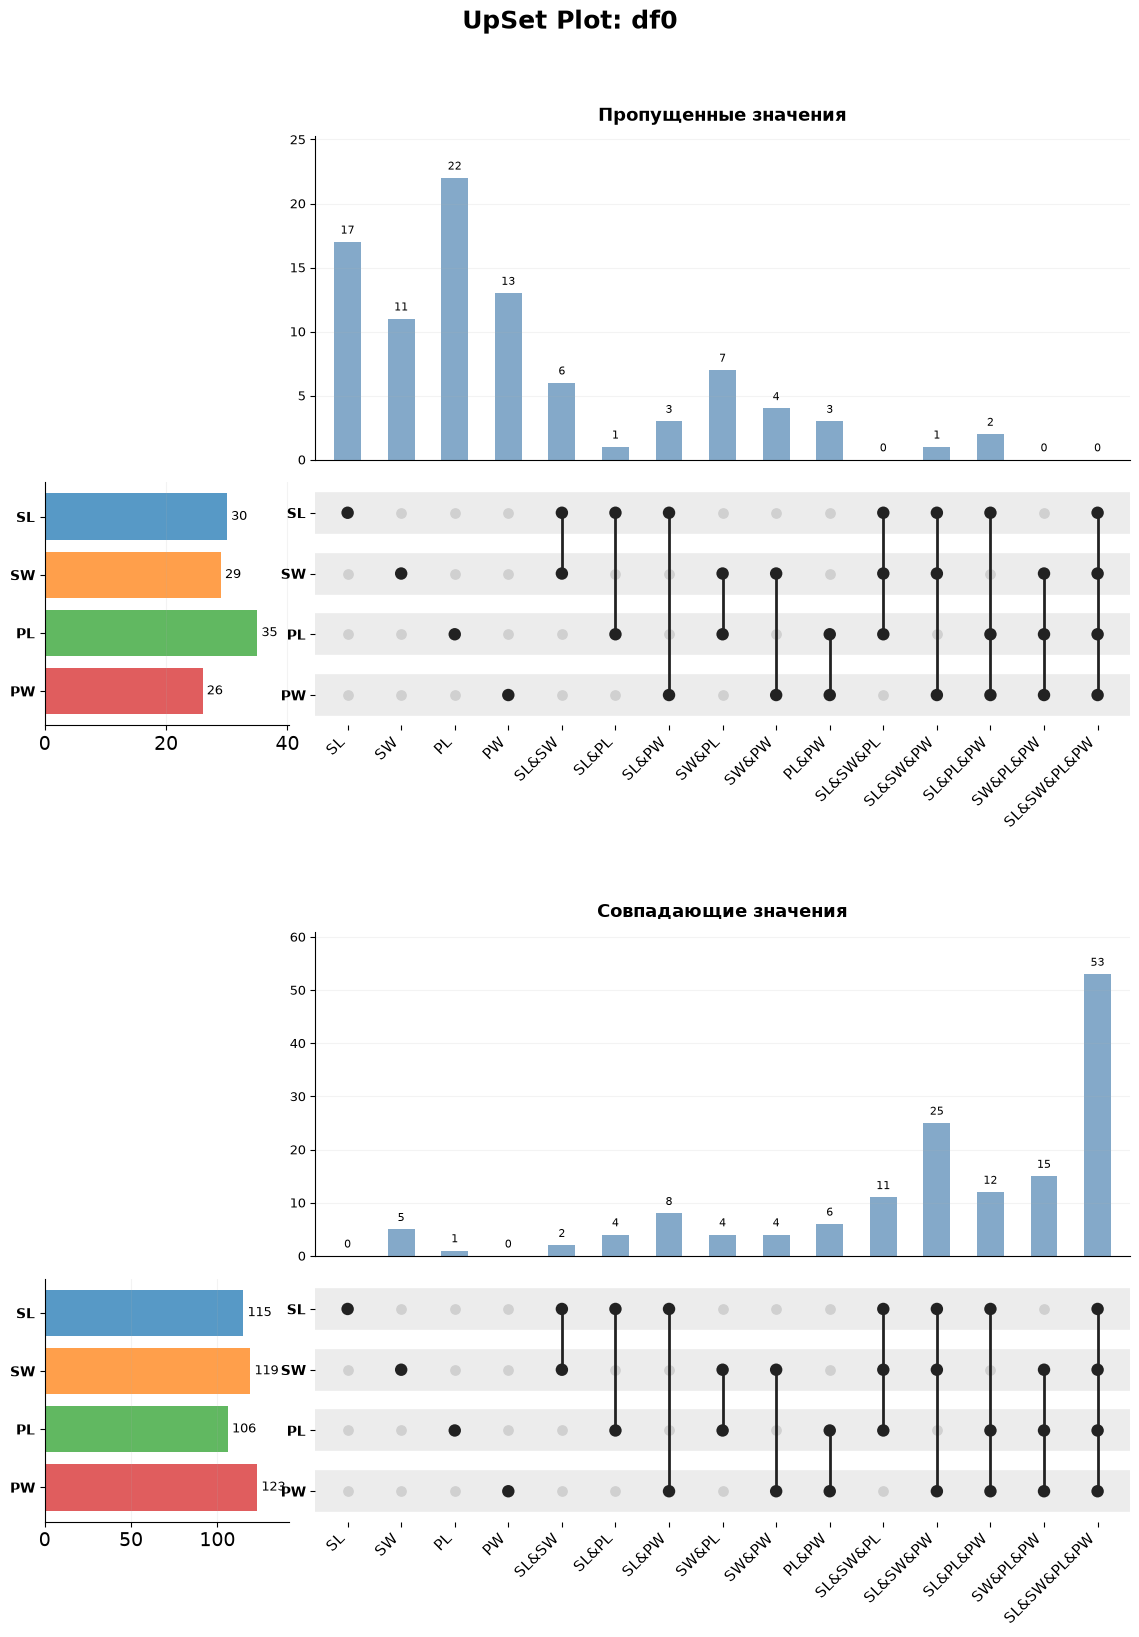

In [83]:
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

FEATURE_COLORS = {
    'SL': '#1f77b4',
    'SW': '#ff7f0e',
    'PL': '#2ca02c',
    'PW': '#d62728'
}

def compute_intersections(df, indicator_cols):
    intersections = {}
    for r in range(1, len(indicator_cols) + 1):
        for combo in combinations(range(len(indicator_cols)), r):
            selected = [indicator_cols[i] for i in combo]
            other = [col for i, col in enumerate(indicator_cols) if i not in combo]
            mask = df[selected].all(axis=1)
            if other:
                mask &= ~df[other].any(axis=1)
            intersections[combo] = mask.sum()
    return intersections

def similar_values_mask(series, tolerance=0.01):
    values = series.to_numpy(dtype=float)
    mask = np.zeros(len(values), dtype=bool)
    valid = np.isfinite(values)
    indices = np.where(valid)[0]
    if len(indices) < 2:
        return mask
    order = indices[np.argsort(values[indices])]
    sorted_values = values[order]
    close = np.diff(sorted_values) < tolerance
    mask[order[:-1][close]] = True
    mask[order[1:][close]] = True
    return mask

def plot_upset_axes(fig, gs, intersections, title, set_labels):
    combinations_list = list(intersections.keys())
    values = np.array([intersections[c] for c in combinations_list])
    x = np.arange(len(combinations_list))
    max_value = max(values.max(), 1)

    subgs = gs.subgridspec(
        2, 2,
        width_ratios=[1.5, 5],
        height_ratios=[4, 3],
        wspace=0.05,
        hspace=0.08
    )

    ax_set = fig.add_subplot(subgs[1, 0])
    ax_bar = fig.add_subplot(subgs[0, 1])
    ax_matrix = fig.add_subplot(subgs[1, 1])

    # Верхняя гистограмма пересечений
    ax_bar.bar(
        x, values,
        width=0.5,
        color='#5b8db8',
        alpha=0.75,
        edgecolor='none'
    )

    for i, value in enumerate(values):
        ax_bar.text(
            i,
            value + max_value * 0.02,
            str(value),
            ha='center',
            va='bottom',
            fontsize=8
        )

    ax_bar.set_title(
        title,
        fontsize=13,
        fontweight='bold',
        loc='center',
        y=1.02
    )

    ax_bar.set_xlim(-0.6, len(x) - 0.4)
    ax_bar.set_ylim(0, max_value * 1.15)
    ax_bar.set_xticks([])

    ax_bar.tick_params(
        axis='y',
        labelsize=9
    )

    ax_bar.spines[['top', 'right']].set_visible(False)
    ax_bar.grid(axis='y', alpha=0.15)

    # Левая часть — количество объектов в каждом признаке
    set_counts = []

    for feature in set_labels:
        set_counts.append(
            sum(
                value
                for combo, value in intersections.items()
                if features.index(feature) in combo
            )
        )

    y = np.arange(len(set_labels))

    ax_set.barh(
        y,
        set_counts,
        color=[FEATURE_COLORS[f] for f in set_labels],
        alpha=0.75,
        edgecolor='none'
    )

    ax_set.set_yticks(y)
    ax_set.set_yticklabels(
        set_labels,
        fontsize=10,
        fontweight='bold'
    )

    ax_set.invert_yaxis()
    ax_set.set_xlim(0, max(set_counts + [1]) * 1.15)

    ax_set.spines[['top', 'right']].set_visible(False)
    ax_set.grid(axis='x', alpha=0.15)

    for i, value in enumerate(set_counts):
        ax_set.text(
            value + max(set_counts + [1]) * 0.02,
            i,
            str(value),
            va='center',
            fontsize=9
        )

    # Матрица комбинаций
    ax_matrix.set_xlim(-0.6, len(x) - 0.4)
    ax_matrix.set_ylim(-0.5, len(set_labels) - 0.5)
    ax_matrix.invert_yaxis()

    for row in range(len(set_labels)):
        ax_matrix.axhline(
            row,
            color='gray',
            alpha=0.15,
            linewidth=30
        )

    # Серые базовые точки
    for i in x:
        for row in range(len(set_labels)):
            ax_matrix.scatter(
                i,
                row,
                s=45,
                color='#d0d0d0',
                zorder=2
            )

    # Активные точки и соединения
    for i, combo in enumerate(combinations_list):
        rows = list(combo)

        if len(rows) > 1:
            ax_matrix.plot(
                [i, i],
                [min(rows), max(rows)],
                color='#222222',
                linewidth=2,
                zorder=3
            )

        for row in rows:
            ax_matrix.scatter(
                i,
                row,
                s=80,
                color='#222222',
                edgecolor='none',
                zorder=4
            )

    ax_matrix.set_yticks(np.arange(len(set_labels)))
    ax_matrix.set_yticklabels(
        set_labels,
        fontsize=10,
        fontweight='bold'
    )
    ax_matrix.set_xticks(x)

    labels = [
        '&'.join(set_labels[i] for i in combo)
        for combo in combinations_list
    ]

    ax_matrix.set_xticklabels(
        labels,
        rotation=45,
        ha='right',
        fontsize=11
    )

    ax_matrix.spines[['top', 'right', 'left', 'bottom']].set_visible(False)

    return ax_set, ax_bar, ax_matrix

def plot_one_dataset_panel(df, dataset_name):
    # 1. Пропуски
    missing_flags = df[features].isna()
    missing_intersections = compute_intersections(
        missing_flags,
        features
    )

    # 2. Совпадающие значения
    similar_flags = pd.DataFrame({
        feature: similar_values_mask(df[feature], tolerance=0.1)
        for feature in features
    })

    similar_intersections = compute_intersections(
        similar_flags,
        features
    )

    fig = plt.figure(figsize=(14, 18))

    outer = fig.add_gridspec(
        2, 1,
        height_ratios=[1, 1],
        hspace=0.35
    )

    plot_upset_axes(
        fig,
        outer[0],
        missing_intersections,
        f'Пропущенные значения',
        features
    )

    plot_upset_axes(
        fig,
        outer[1],
        similar_intersections,
        f'Совпадающие значения',
        features
    )

    fig.suptitle(
        f'UpSet Plot: {dataset_name}',
        fontsize=18,
        fontweight='bold',
        y=0.95
    )

    plt.show()

#----------------------------------------------
abbrevs = features
plot_one_dataset_panel(df0, 'df0')


### **[2.4]** Формирование отфильтрованного датасета `df0m`
- Выбрать **три класса** и **четыре количественных (недискретных) признака**.
- Сформировать на их основе «отфильтрованный» датасет `df0m` для дальнейшего анализа, **удалив из датасета все объекты**, для которых не определены значения хотя бы одного из выбранных четырёх количественных признаков.

---


In [84]:
SELECTED_CLASSES = [0, 1, 2] # setosa=0, versicolor=1, virginica=2
SELECTED_FEATURES = ['SL', 'SW', 'PL','PW']

mask_class = df0[target].isin(SELECTED_CLASSES)
mask_complete = df0[SELECTED_FEATURES].notna().all(axis=1)

# --- Сборка df0m ---
df0m = df0[mask_class & mask_complete].copy()
df0m = df0m[SELECTED_FEATURES + [target]].reset_index(drop=True)

display(df0m.head(5))

# Число объектов с NaN по классам
print('Число объектов с NaN по классам: ')
print(df0m.groupby(target).apply(lambda g: g.isna().any(axis=1).sum()))

,SL,SW,PL,PW,Species
0,4.7,3.2,1.3,0.2,0
1,5.4,3.9,1.7,0.4,0
2,5.0,3.4,1.5,0.2,0
3,4.4,2.9,1.4,0.2,0
4,5.4,3.7,1.5,0.2,0


Число объектов с NaN по классам: 
Species
0    0
1    0
2    0
dtype: int64



### **[2.5]** Сравнение корреляций Пирсона
Для датасетов `df0` и `df0m` сравнительно вывести корреляции Пирсона, как в [1.5].

---

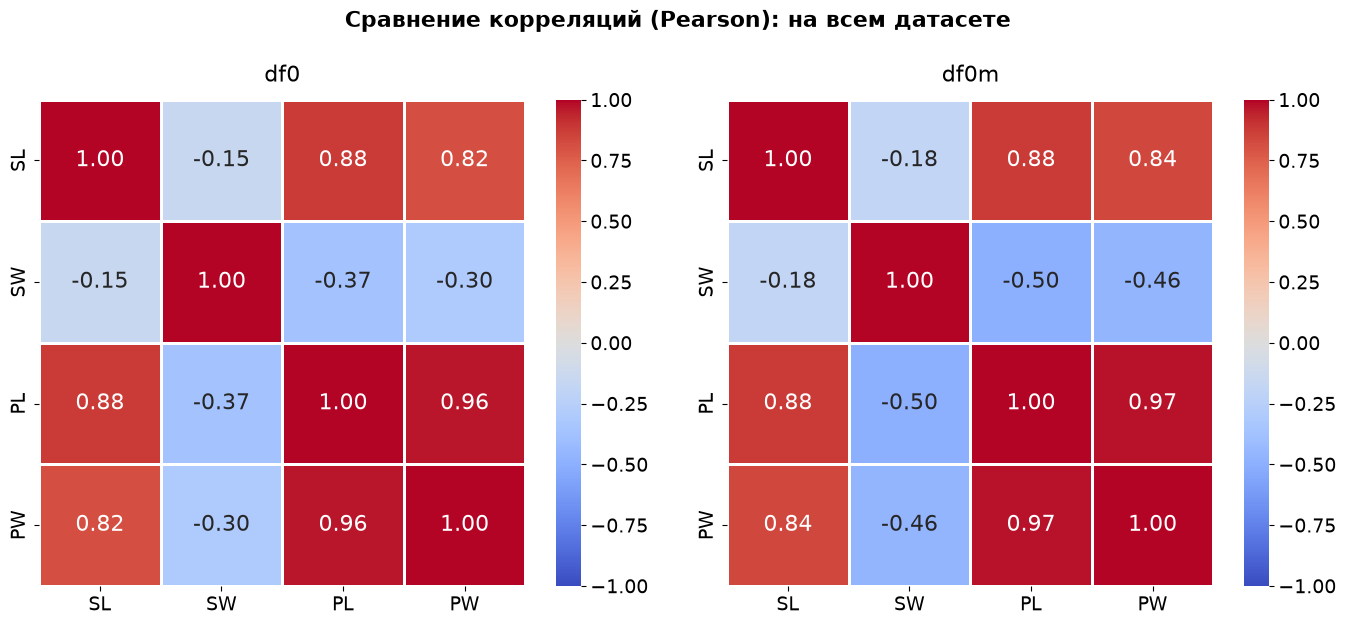

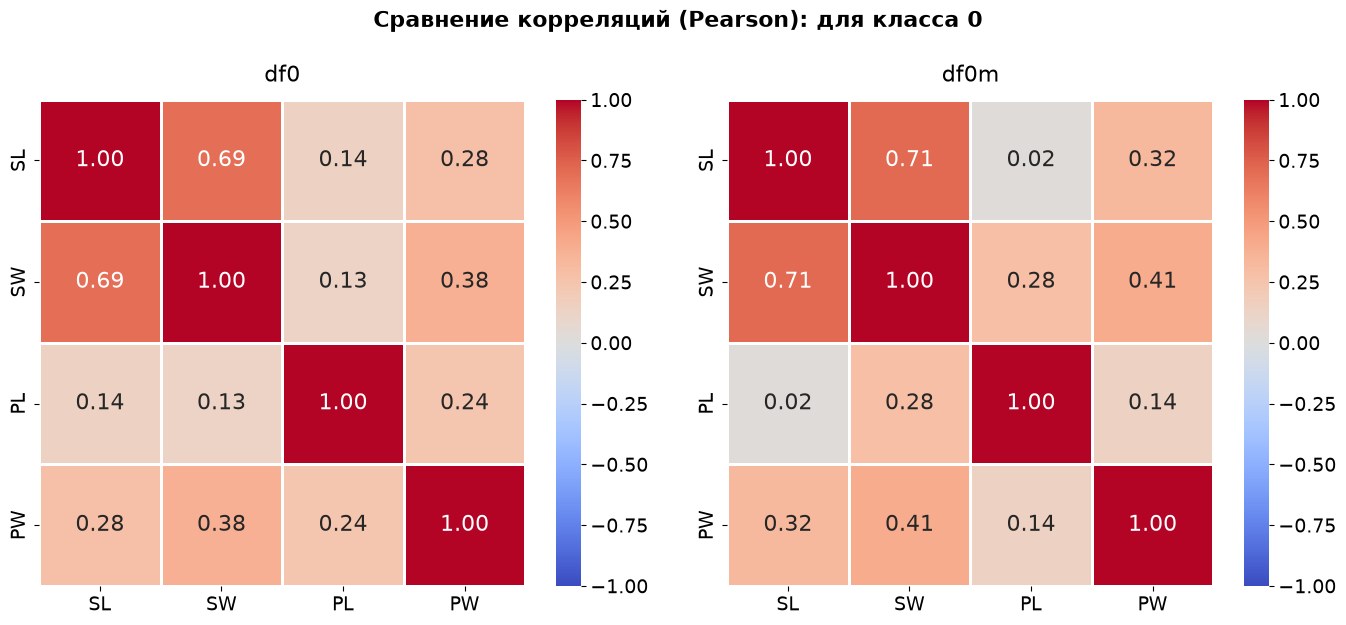

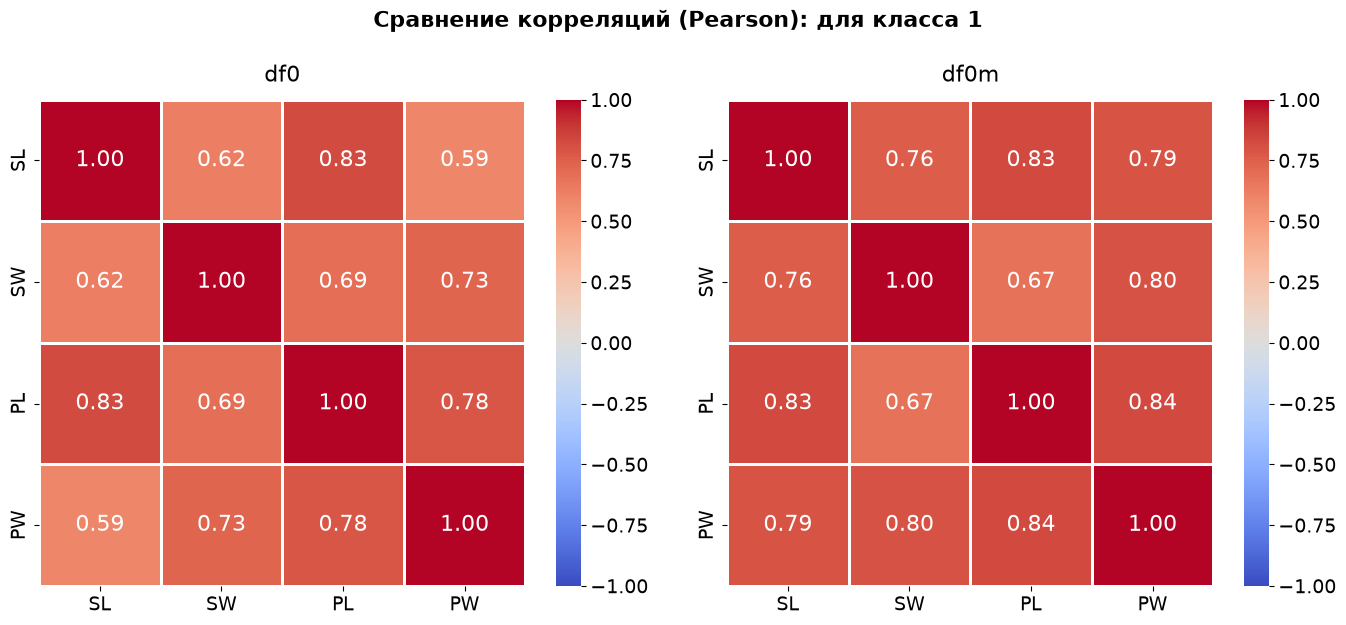

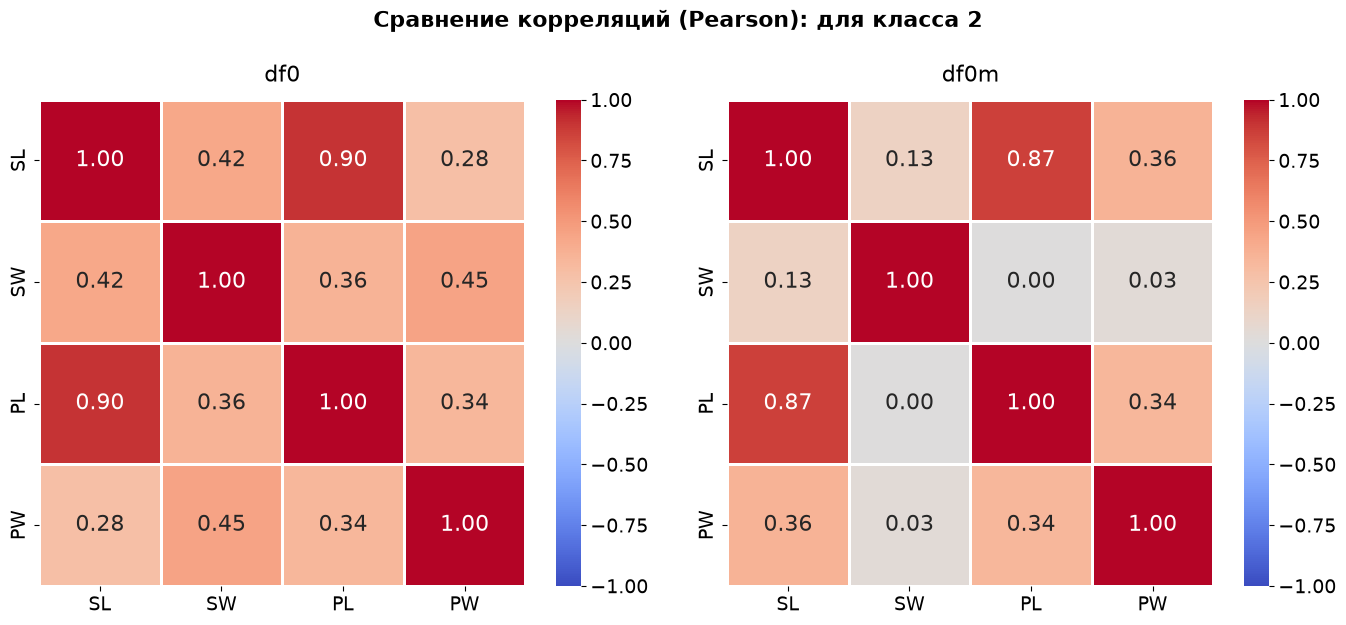

In [85]:
import seaborn as sns
import matplotlib.pyplot as plt

def compare_correlations(df1, df2, target, name1="df0", name2="df0m"):

    features = [c for c in df1.columns if c != target]
    classes = sorted(df1[target].unique())
    
    def plot_side_by_side(data1, data2, title_suffix, method):
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        fig.suptitle(f'Сравнение корреляций ({method.capitalize()}): {title_suffix}', 
                     fontsize=16, fontweight='bold', y=1.02)
        
        # Первый датасет
        corr1 = data1[features].corr(method=method)
        sns.heatmap(corr1, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0,
                    fmt='.2f', linewidths=1, linecolor='white', ax=axes[0], square=True)
        axes[0].set_title(f'{name1}', y=1.02)
        
        # Второй датасет
        corr2 = data2[features].corr(method=method)
        sns.heatmap(corr2, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0,
                    fmt='.2f', linewidths=1, linecolor='white', ax=axes[1], square=True)
        axes[1].set_title(f'{name2}', y=1.02)
        
        plt.tight_layout()
        plt.show()

    plot_side_by_side(df1, df2, "на всем датасете", "pearson")
    
    for cls in classes:
        df1_cls = df1[df1[target] == cls]
        df2_cls = df2[df2[target] == cls]
        
        plot_side_by_side(df1_cls, df2_cls, f"для класса {cls}", "pearson")


compare_correlations(df0, df0m, target, name1="df0", name2="df0m")


### **[2.6]** Визуализация по всем парам переменных
Выполнить визуализацию датасета по всем парам выбранных переменных, показав:
- на графиках **разных пар признаков** — объекты классов разными по форме/цвету точками;
- в графиках с **одной и той же парой переменных** — диаграммы плотности распределения каждого класса по оси признака.

---

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoLocator, AutoMinorLocator
from matplotlib.lines import Line2D
from scipy import stats
from itertools import combinations
import math
import seaborn as sns

# ============================================================
# ГЛОБАЛЬНЫЕ НАСТРОЙКИ ШРИФТА
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 16
plt.rcParams['axes.labelsize'] = 16
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 12


def custom_scatter(
    ax, x, y,                          # объект Axes и массивы координат X, Y
    class_values=None,                 # массив классов точек (0/1) для раскраски
    
    # === Шрифт ===
    font_family="DejaVu Sans",         # семейство шрифта для всех текстовых элементов
    font_size=16,                      # базовый размер шрифта
    
    # === Точки ===
    point_size=30,                     # размер маркеров точек
    point_alpha=0.55,                  # прозрачность точек (0..1)
    point_colors=None,                 # цвета для классов (None = авто)
    point_edgecolor="none",            # цвет обводки точек
    point_linewidth=0.5,               # толщина обводки точек
    point_marker="o",                  # форма маркера ("o" - круг, "s" - квадрат)
    
    # === Рамка ===
    spine_color="black",               # цвет рамок осей
    spine_width=1.5,                   # толщина рамок осей
    show_top_spine=True,               # показывать верхнюю рамку
    show_right_spine=True,             # показывать правую рамку
    
    # === Деления ===
    major_step="auto",                 # шаг основных делений (число или "auto")
    minor_step="auto",                 # шаг промежуточных делений (число или "auto")
    n_minor_ticks=4,                   # количество промежуточных делений между основными
    tick_length=6,                     # длина основных делений
    minor_tick_length=3,               # длина промежуточных делений
    tick_width=1.5,                    # толщина основных делений
    minor_tick_width=1,                # толщина промежуточных делений
    tick_direction="out",              # направление делений ("out", "in", "inout")
    tick_label_size=None,              # размер цифр на осях (None = font_size - 2)
    tick_label_color="black",          # цвет цифр на осях
    
    # === Сетка ===
    show_grid=True,                    # показывать сетку
    grid_which="major",                # по каким делениям рисовать сетку ("major", "minor", "both")
    grid_color="gray",                 # цвет сетки
    grid_alpha=0.25,                   # прозрачность сетки
    grid_linestyle="--",               # стиль линии сетки ("-", "--", ":", "-.")
    grid_linewidth=0.5,                # толщина линий сетки
    
    # === Подписи ===
    xlabel=None,                       # подпись оси X
    ylabel=None,                       # подпись оси Y
    label_size=None,                   # размер подписей осей (None = font_size)
    label_weight="normal",             # начертание подписей ("normal", "bold")
    
    # === Заголовок ===
    title=None,                        # заголовок графика
    title_size=None,                   # размер заголовка (None = font_size)
    title_weight="bold",               # начертание заголовка
    
    # === Регрессия ===
    show_correlation=True,             # показывать линию регрессии
    correlation_color="darkred",       # цвет линии регрессии
    correlation_width=2,               # толщина линии регрессии
    
    # === Доверительный интервал линии регрессии ===
    show_confidence_band=True,         # показывать доверительный интервал для линии регрессии
    confidence_band_color="orange",    # цвет доверительного интервала
    confidence_band_alpha=0.2,         # прозрачность доверительного интервала
    confidence_band_linestyle="-",     # стиль линии границ доверительного интервала
    confidence_band_linewidth=1,       # толщина линии границ доверительного интервала
    confidence_band_level=0.95,        # уровень доверия (0.95 = 95%)
    
    # === Интервал предсказания ===
    show_prediction_interval=True,     # показывать интервал предсказания для новых точек
    confidence_level=0.95,             # уровень доверия интервала предсказания
    interval_color="lightblue",        # цвет интервала предсказания
    interval_alpha=0.3,                # прозрачность интервала предсказания
    interval_linestyle="--",           # стиль линии границ интервала предсказания
    interval_linewidth=1,              # толщина линии границ интервала предсказания
    
    # === Интервалы значений ===
    show_intervals=True,               # показывать информацию об интервалах ΔX
    interval_position="top",           # положение текста интервалов ("top", "bottom")
    
    # === Легенда ===
    show_legend=True,                  # показывать легенду
    legend_loc="upper right",          # расположение легенды
    legend_fontsize=None,              # размер шрифта легенды (None = font_size - 4)
    legend_framealpha=0.9,             # прозрачность фона легенды
    
    # === Масштаб ===
    x_lim=None,                        # пределы оси X (min, max) или None для авто
    y_lim=None,                        # пределы оси Y (min, max) или None для авто
    equal_scale=False,                 # одинаковый физический масштаб осей X и Y
):
    """
    Построение scatter plot с регрессией, доверительным интервалом 
    и интервалом предсказания.
    """
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    
    # Значения по умолчанию для размеров шрифтов
    if tick_label_size is None:
        tick_label_size = max(font_size - 2, 8)
    if label_size is None:
        label_size = font_size
    if title_size is None:
        title_size = font_size
    if legend_fontsize is None:
        legend_fontsize = max(font_size - 4, 8)
    
    # --- Scatter ---
    if class_values is not None:
        classes = np.unique(class_values[~np.isnan(class_values)])
        
        if point_colors is None:
            colors = plt.cm.tab10(np.linspace(0, 1, max(len(classes), 1)))
        elif isinstance(point_colors, str):
            colors = [point_colors] * len(classes)
        else:
            colors = point_colors
        
        for cls, color in zip(classes, colors):
            mask = class_values == cls
            ax.scatter(
                x[mask], y[mask],
                s=point_size,
                alpha=point_alpha,
                color=color,
                marker=point_marker,
                edgecolors=point_edgecolor,
                linewidths=point_linewidth,
                label=f"Класс {int(cls)}",
                zorder=3
            )
    else:
        color = point_colors if isinstance(point_colors, str) else "steelblue"
        ax.scatter(
            x, y,
            s=point_size,
            alpha=point_alpha,
            color=color,
            marker=point_marker,
            edgecolors=point_edgecolor,
            linewidths=point_linewidth,
            zorder=3
        )
    
    # --- Корреляция и интервалы ---
    r = None
    dx_mean = None
    dx_median = None
    a = None
    b = None
    x_line = None
    y_line = None
    n = None
    x_mean = None
    residual_std = None
    ss_x = None
    
    if show_correlation and len(x) > 1:
        r = np.corrcoef(x, y)[0, 1]
        a, b = np.polyfit(x, y, 1)
        
        x_line = np.linspace(x.min(), x.max(), 300)
        y_line = a * x_line + b
        
        n = len(x)
        x_mean = np.mean(x)
        y_pred = a * x + b
        residuals = y - y_pred
        residual_std = np.sqrt(np.sum(residuals**2) / (n - 2))
        ss_x = np.sum((x - x_mean)**2)
        
        # Линия регрессии
        ax.plot(
            x_line, y_line,
            color=correlation_color,
            lw=correlation_width,
            zorder=4,
            label=f"r = {r:.3f}"
        )
        
        # Доверительный интервал линии регрессии (confidence band)
        if show_confidence_band and ss_x > 0:
            t_crit_ci = stats.t.ppf((1 + confidence_band_level) / 2, df=n-2)
            se_fit = residual_std * np.sqrt(1/n + (x_line - x_mean)**2 / ss_x)
            
            y_ci_upper = y_line + t_crit_ci * se_fit
            y_ci_lower = y_line - t_crit_ci * se_fit
            
            # Заливка доверительного интервала
            ax.fill_between(
                x_line, y_ci_lower, y_ci_upper,
                color=confidence_band_color,
                alpha=confidence_band_alpha,
                zorder=2,
                label=f"{confidence_band_level*100:.0f}% CI (линия)"
            )
            
            # Линии границ доверительного интервала
            ax.plot(
                x_line, y_ci_upper,
                color=confidence_band_color,
                linestyle=confidence_band_linestyle,
                linewidth=confidence_band_linewidth,
                alpha=min(confidence_band_alpha + 0.3, 1.0),
                zorder=3
            )
            ax.plot(
                x_line, y_ci_lower,
                color=confidence_band_color,
                linestyle=confidence_band_linestyle,
                linewidth=confidence_band_linewidth,
                alpha=min(confidence_band_alpha + 0.3, 1.0),
                zorder=3
            )
        
        # Интервал предсказания (prediction interval)
        if show_prediction_interval and ss_x > 0:
            t_crit_pi = stats.t.ppf((1 + confidence_level) / 2, df=n-2)
            se_pred = residual_std * np.sqrt(1 + 1/n + (x_line - x_mean)**2 / ss_x)
            
            y_pi_upper = y_line + t_crit_pi * se_pred
            y_pi_lower = y_line - t_crit_pi * se_pred
            
            ax.fill_between(
                x_line, y_pi_lower, y_pi_upper,
                color=interval_color,
                alpha=interval_alpha,
                zorder=2,
                label=f"{confidence_level*100:.0f}% PI (прогноз)"
            )
            
            ax.plot(
                x_line, y_pi_upper,
                color=interval_color,
                linestyle=interval_linestyle,
                linewidth=interval_linewidth,
                alpha=min(interval_alpha + 0.3, 1.0),
                zorder=3
            )
            ax.plot(
                x_line, y_pi_lower,
                color=interval_color,
                linestyle=interval_linestyle,
                linewidth=interval_linewidth,
                alpha=min(interval_alpha + 0.3, 1.0),
                zorder=3
            )
    
    # --- Delta X ---
    if show_intervals and len(x) > 1:
        dx = np.diff(np.sort(x))
        dx_mean = dx.mean()
        dx_median = np.median(dx)
    
    # --- Легенда ---
    if show_legend:
        legend_elements = []
        
        if class_values is not None:
            classes = np.unique(class_values[~np.isnan(class_values)])
            if point_colors is None:
                colors = plt.cm.tab10(np.linspace(0, 1, max(len(classes), 1)))
            elif isinstance(point_colors, str):
                colors = [point_colors] * len(classes)
            else:
                colors = point_colors
            
            for cls, color in zip(classes, colors):
                legend_elements.append(
                    Line2D([0], [0], marker=point_marker, color='w',
                           markerfacecolor=color, markersize=8,
                           label=f"Класс {int(cls)}")
                )
        
        if r is not None:
            legend_elements.append(
                Line2D([0], [0], marker='', color='w',
                       label=f"r = {r:.3f}")
            )
        
        if show_confidence_band:
            legend_elements.append(
                Line2D([0], [0], marker='', color=confidence_band_color,
                       linestyle='-', linewidth=2, alpha=0.7,
                       label=f"{confidence_band_level*100:.0f}% CI (линия регрессии)")
            )
        
        if show_prediction_interval:
            legend_elements.append(
                Line2D([0], [0], marker='', color=interval_color,
                       linestyle='--', linewidth=2, alpha=0.7,
                       label=f"{confidence_level*100:.0f}% PI (прогноз)")
            )
        
        if legend_elements:
            ax.legend(
                handles=legend_elements,
                loc=legend_loc,
                fontsize=legend_fontsize,
                framealpha=legend_framealpha,
                edgecolor='gray'
            )
    
    # --- Пределы ---
    if x_lim is not None:
        ax.set_xlim(x_lim)
    if y_lim is not None:
        ax.set_ylim(y_lim)
    
    # --- Spines ---
    for name, spine in ax.spines.items():
        spine.set_color(spine_color)
        spine.set_linewidth(spine_width)
    
    ax.spines["top"].set_visible(show_top_spine)
    ax.spines["right"].set_visible(show_right_spine)
    
    # --- Деления ---
    if major_step == "auto":
        ax.xaxis.set_major_locator(AutoLocator())
        ax.yaxis.set_major_locator(AutoLocator())
    else:
        ax.xaxis.set_major_locator(MultipleLocator(major_step))
        ax.yaxis.set_major_locator(MultipleLocator(major_step))
    
    if minor_step == "auto":
        ax.xaxis.set_minor_locator(AutoMinorLocator(n_minor_ticks))
        ax.yaxis.set_minor_locator(AutoMinorLocator(n_minor_ticks))
    else:
        ax.xaxis.set_minor_locator(MultipleLocator(minor_step))
        ax.yaxis.set_minor_locator(MultipleLocator(minor_step))
    
    ax.tick_params(
        which="major",
        direction=tick_direction,
        length=tick_length,
        width=tick_width,
        labelsize=tick_label_size,
        labelcolor=tick_label_color
    )
    ax.tick_params(
        which="minor",
        direction=tick_direction,
        length=minor_tick_length,
        width=minor_tick_width
    )
    
    # --- Grid ---
    if show_grid:
        ax.grid(
            which=grid_which,
            color=grid_color,
            alpha=grid_alpha,
            linestyle=grid_linestyle,
            linewidth=grid_linewidth
        )
    
    # --- Labels ---
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=label_size, fontweight=label_weight, fontfamily=font_family)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=label_size, fontweight=label_weight, fontfamily=font_family)
    if title is not None:
        ax.set_title(title, fontsize=title_size, fontweight=title_weight, fontfamily=font_family)
    
    if equal_scale:
        ax.set_aspect("equal", adjustable="box")
    
    return ax


def make_kde(
    ax,
    df,
    feature,
    class_col="class",
    font_family="DejaVu Sans",
    font_size=16,
    kde_alpha=0.25,
    kde_linewidth=2,
    show_legend=True,
    show_grid=True,
):
    """KDE распределения одного признака отдельно по классам."""

    if class_col not in df.columns:
        raise ValueError(f"Колонка класса '{class_col}' не найдена в DataFrame.")

    classes = sorted(df[class_col].dropna().unique())

    # Общий диапазон признака, чтобы все KDE на диагонали имели
    # одинаковую x-шкалу для данного признака.
    feature_values = df[feature].dropna()
    if len(feature_values) == 0:
        ax.set_title(f"KDE: {feature}", fontsize=font_size, fontweight="bold")
        return ax

    for cls in classes:
        values = df.loc[df[class_col] == cls, feature].dropna().astype(float)

        # KDE требует минимум двух наблюдений и ненулевую дисперсию.
        if len(values) < 2:
            continue

        if np.isclose(values.std(ddof=1), 0):
            # Для константного распределения рисуем вертикальную линию,
            # чтобы KDE не падал.
            ax.axvline(
                values.iloc[0],
                linewidth=kde_linewidth,
                label=f"Класс {int(cls)}"
            )
            continue

        sns.kdeplot(
            x=values,
            ax=ax,
            fill=True,
            alpha=kde_alpha,
            linewidth=kde_linewidth,
            label=f"Класс {int(cls)}",
        )

    ax.set_title(
        f"KDE: {feature}",
        fontsize=font_size,
        fontweight="bold",
        fontfamily=font_family,
    )
    ax.set_xlabel(feature, fontsize=font_size, fontfamily=font_family)
    ax.set_ylabel("Плотность", fontsize=font_size, fontfamily=font_family)

    if show_grid:
        ax.grid(True, alpha=0.2, linestyle="--")

    if show_legend and ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=max(font_size - 4, 8))

    return ax


def plot_pairs(
    df,                                # DataFrame с данными
    class_col="class",                 # название колонки с классами
    features=None,                     # список признаков (None = все кроме class_col)
    
    # === Размер панно ===
    subplot_size=6,                    # размер одного subplot в дюймах
    max_cols=3,                        # максимальное количество столбцов в панно
    padding=0.05,                      # отступ для global limits (доля от диапазона)
    
    # === Шрифт ===
    font_family="DejaVu Sans",         # семейство шрифта
    font_size=16,                      # базовый размер шрифта
    
    # === Точки ===
    point_size=30,                     # размер маркеров
    point_color=None,                  # цвет маркеров (None = авто по классам)
    point_alpha=0.55,                  # прозрачность маркеров
    point_edgecolor="none",            # цвет обводки маркеров
    point_linewidth=0.5,               # толщина обводки маркеров
    point_marker="o",                  # форма маркера
    
    # === Регрессия ===
    show_correlation=True,             # показывать линию регрессии
    correlation_color="darkred",       # цвет линии регрессии
    correlation_width=2,               # толщина линии регрессии
    
    # === Доверительный интервал линии регрессии ===
    show_confidence_band=True,         # показывать доверительный интервал для линии
    confidence_band_color="orange",    # цвет доверительного интервала
    confidence_band_alpha=0.2,         # прозрачность доверительного интервала
    confidence_band_linestyle="-",     # стиль линии границ
    confidence_band_linewidth=1,       # толщина линии границ
    confidence_band_level=0.95,        # уровень доверия
    
    # === Интервал предсказания ===
    show_prediction_interval=True,     # показывать интервал предсказания
    confidence_level=0.95,             # уровень доверия
    interval_color="lightblue",        # цвет интервала
    interval_alpha=0.3,                # прозрачность интервала
    interval_linestyle="--",           # стиль линии границ
    interval_linewidth=1,              # толщина линии границ
    
    # === Интервалы значений ===
    show_intervals=True,               # показывать информацию об интервалах ΔX
    
    # === Легенда ===
    show_legend=True,                  # показывать легенду
    
    # === Сетка ===
    show_grid=True,                    # показывать сетку
    
    # === Масштаб ===
    equal_scale=False,                 # одинаковый физический масштаб осей
    scale_mode="global",               # режим масштаба ("global" - общий, "individual" - индивидуальный)
    
    # === Заголовок фигуры ===
    suptitle="Все пары признаков",     # общий заголовок фигуры
    suptitle_size=18,                  # размер общего заголовка
):
    # Определяем признаки
    if features is None:
        features = [c for c in df.columns if c != class_col]
    
    from itertools import product

    pairs = list(product(features, repeat=2))
    n_pairs = len(pairs)
    
    if n_pairs == 0:
        print("Недостаточно признаков для построения пар.")
        return
    
    # Создаём фигуру оптимального размера
    n = len(features)
    fig, axes = plt.subplots(
        n, n,
        figsize=(6 * n, 6 * n),
        squeeze=False
    )
    axes = axes.flatten()
    
    # Общий масштаб
    global_lim = None
    if scale_mode == "global":
        values = df[features].values
        vmin = values.min()
        vmax = values.max()
        d = vmax - vmin
        global_lim = (vmin - d * padding, vmax + d * padding)
    
    for idx, (ax, (x_name, y_name)) in enumerate(zip(axes, pairs)):

        # ========================================================
        # ДИАГОНАЛЬ → KDE признака по классам
        # ========================================================
        if x_name == y_name:
            make_kde(
                ax=ax,
                df=df,
                feature=x_name,
                class_col=class_col,
                font_family=font_family,
                font_size=font_size,
                kde_alpha=0.25,
                kde_linewidth=2,
                show_legend=show_legend,
                show_grid=show_grid,
            )

            # Для KDE не используем глобальный квадратный масштаб.
            if scale_mode == "global":
                feature_values = df[x_name].dropna().astype(float)
                if len(feature_values) > 0:
                    vmin = feature_values.min()
                    vmax = feature_values.max()
                    d = vmax - vmin
                    if d > 0:
                        ax.set_xlim(vmin - d * padding, vmax + d * padding)

            continue

        # ========================================================
        # ВНЕ ДИАГОНАЛИ → обычный scatter
        # ========================================================
        if scale_mode == "individual":
            x_lim = None
            y_lim = None
        else:
            x_lim = global_lim
            y_lim = global_lim

        custom_scatter(
            ax=ax,
            x=df[x_name],
            y=df[y_name],
            class_values=df[class_col] if class_col in df.columns else None,

            # Шрифт
            font_family=font_family,
            font_size=font_size,

            # Точки
            point_size=point_size,
            point_colors=point_color,
            point_alpha=point_alpha,
            point_edgecolor=point_edgecolor,
            point_linewidth=point_linewidth,
            point_marker=point_marker,

            # Регрессия
            show_correlation=show_correlation,
            correlation_color=correlation_color,
            correlation_width=correlation_width,

            # Доверительный интервал
            show_confidence_band=show_confidence_band,
            confidence_band_color=confidence_band_color,
            confidence_band_alpha=confidence_band_alpha,
            confidence_band_linestyle=confidence_band_linestyle,
            confidence_band_linewidth=confidence_band_linewidth,
            confidence_band_level=confidence_band_level,

            # Интервал предсказания
            show_prediction_interval=show_prediction_interval,
            confidence_level=confidence_level,
            interval_color=interval_color,
            interval_alpha=interval_alpha,
            interval_linestyle=interval_linestyle,
            interval_linewidth=interval_linewidth,

            # Интервалы
            show_intervals=show_intervals,

            # Легенда
            show_legend=show_legend,

            # Сетка
            show_grid=show_grid,

            # Масштаб
            x_lim=x_lim,
            y_lim=y_lim,
            equal_scale=equal_scale,

            # Подписи
            xlabel=x_name,
            ylabel=y_name,
            title=f"{x_name} × {y_name}",
        )

    # Скрываем неиспользуемые оси
    for idx in range(n_pairs, len(axes)):
        axes[idx].axis('off')
    
    fig.suptitle(suptitle, fontsize=suptitle_size, fontweight="bold", fontfamily=font_family, y=1.02)
    plt.tight_layout()
    plt.show()

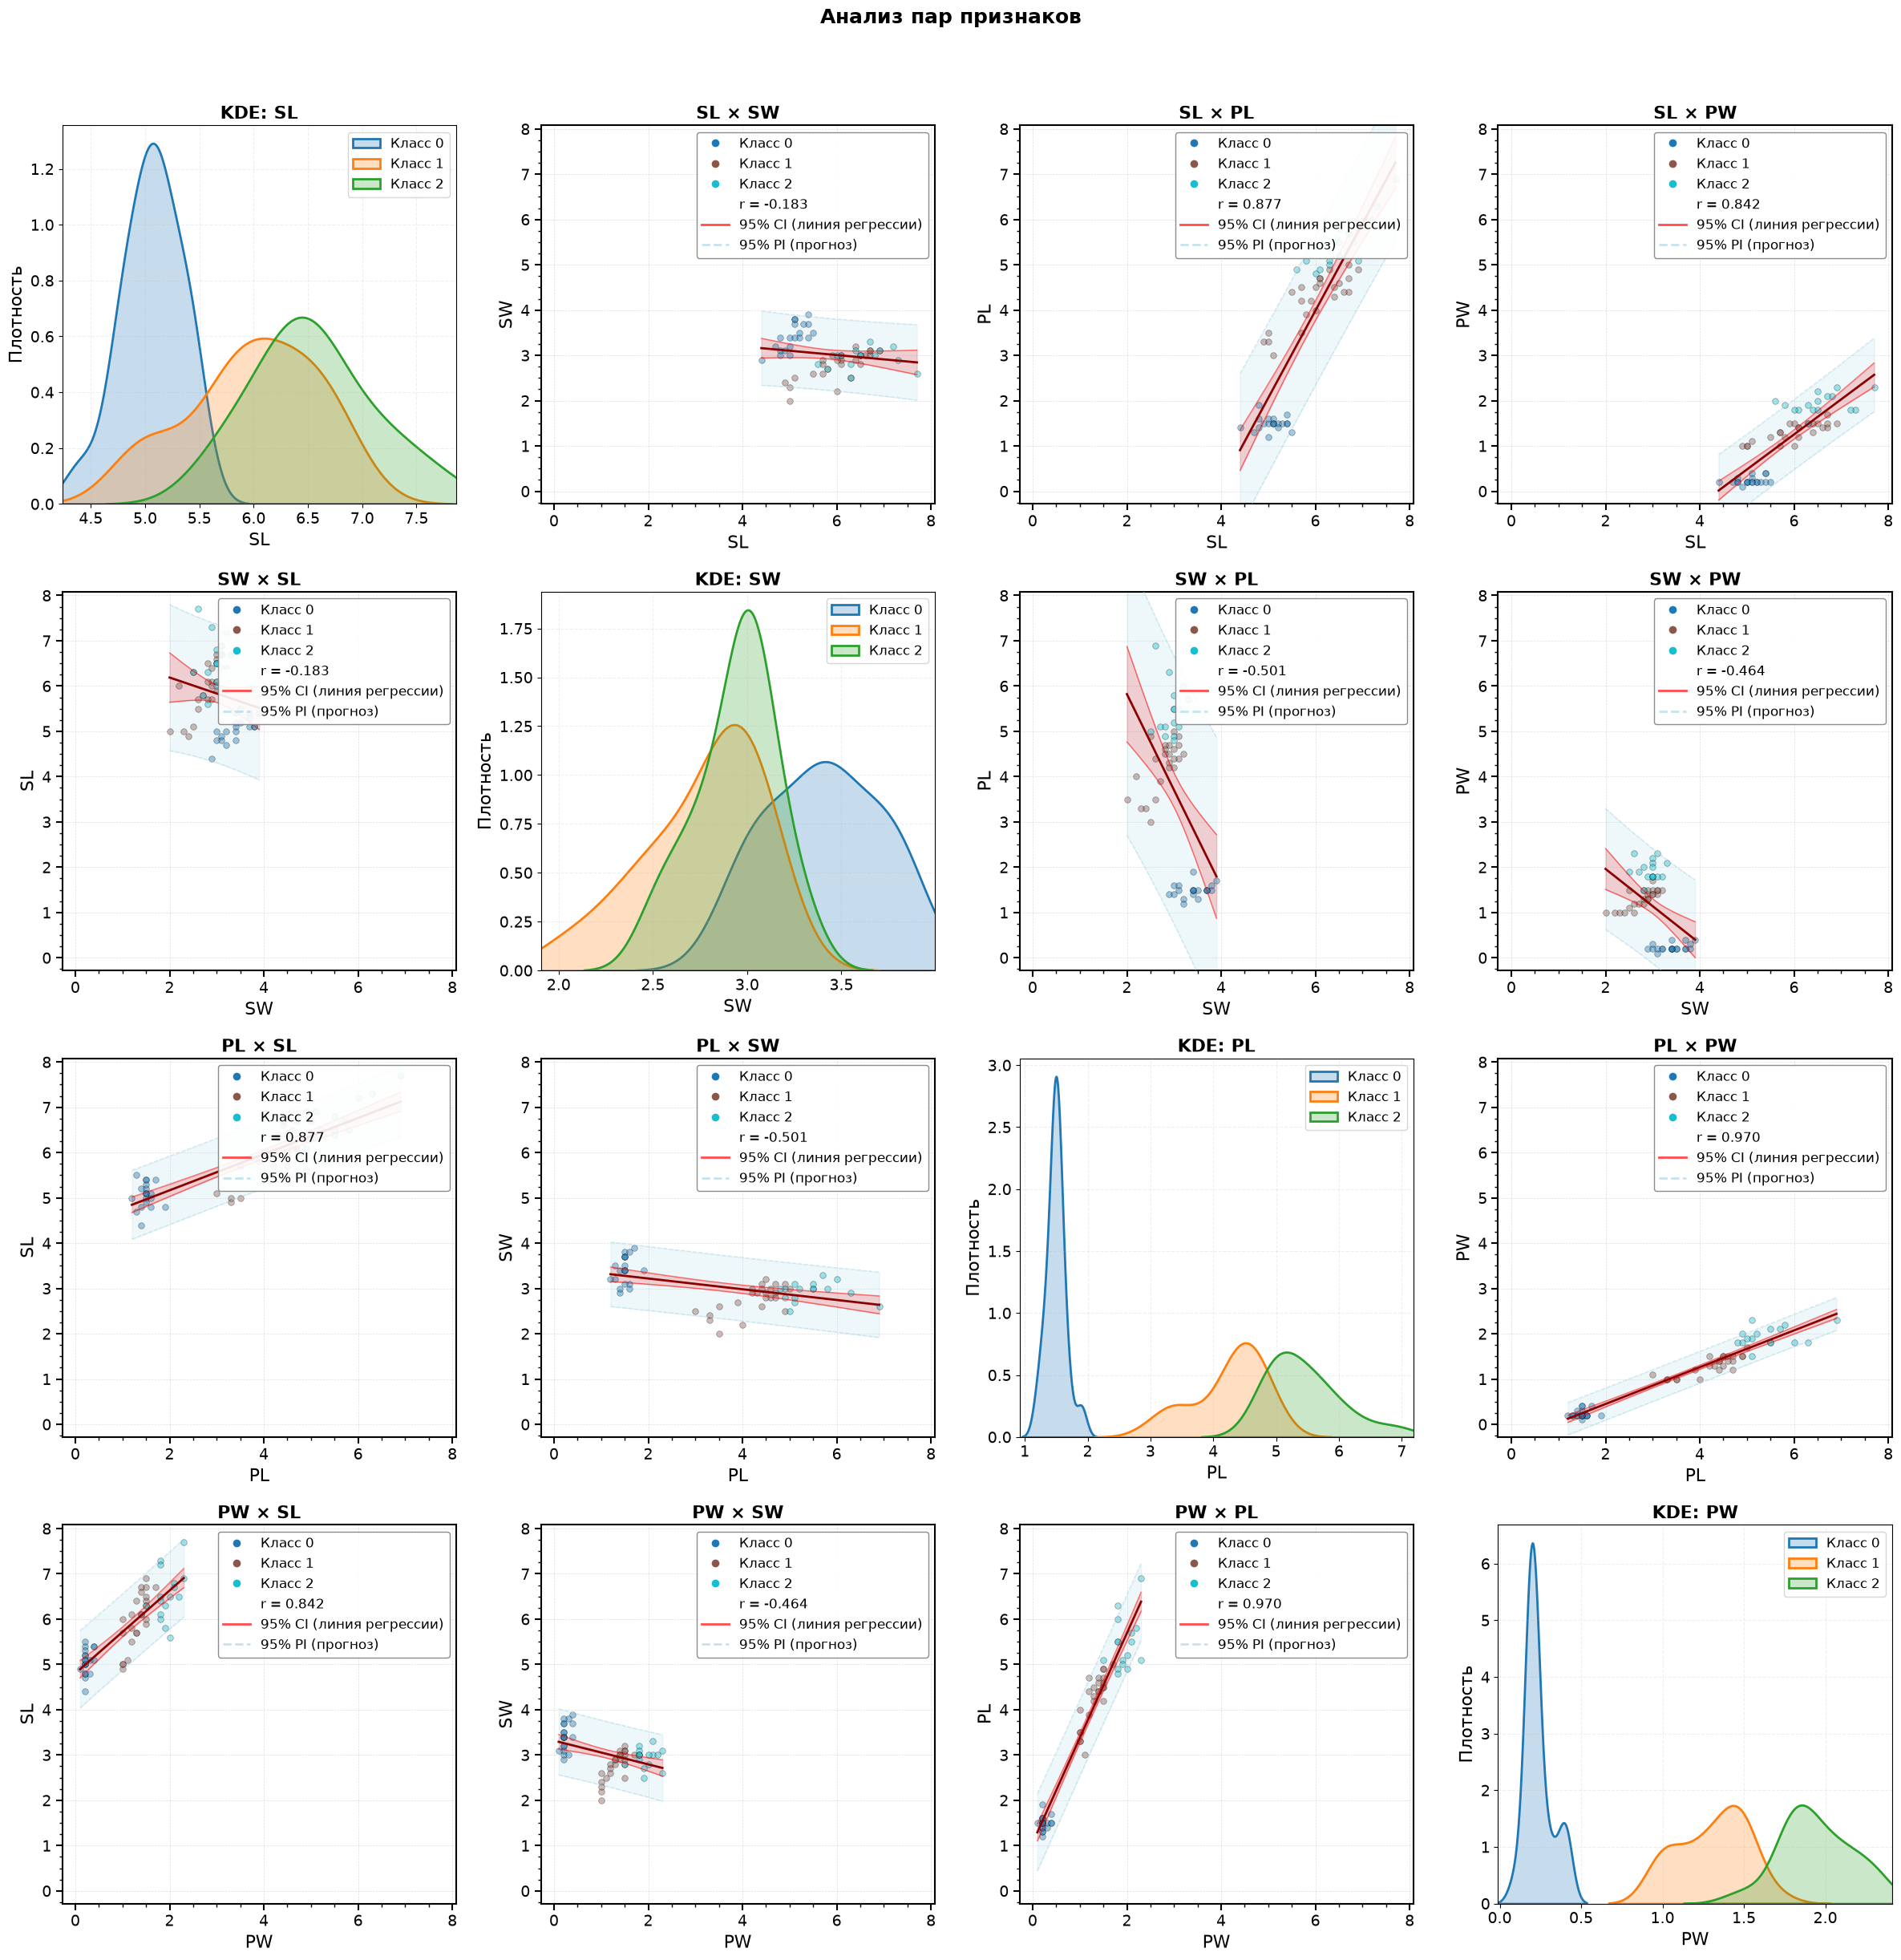

In [87]:
plot_pairs(
    df0m,
    class_col="Species",
    features=["SL", "SW", "PL", "PW"],
    
    # Размер панно
    subplot_size=7,
    max_cols=2,
    
    # Шрифт
    font_family="DejaVu Sans",
    font_size=16,
    
    # Точки
    point_size=30,
    point_color=None,  # автоматические цвета по классам
    point_alpha=0.4,
    point_edgecolor="black",
    point_linewidth=0.5,
    point_marker="o",  # "o" - круг, "s" - квадрат
    
    # Регрессия
    show_correlation=True,
    correlation_color="darkred",
    correlation_width=2,
    
    # Интервал предсказания
    show_prediction_interval=True,
    confidence_level=0.95,
    interval_color="lightblue",
    interval_alpha=0.2,
    interval_linestyle="--",
    interval_linewidth=1,
    
    # Интервалы значений
    show_intervals=True,
    
    # Легенда
    show_legend=True,
    
    # Сетка
    show_grid=True,
    
    # Масштаб
    equal_scale=False,
    scale_mode="global",
    
    suptitle="Анализ пар признаков",
    suptitle_size=18,
    
    # Доверительный интервал линии регрессии
    show_confidence_band=True,
    confidence_band_color="red",
    confidence_band_alpha=0.2,
    confidence_band_level=0.95,
)

### **[2.7]** Одиночный scatterplot с полосами регрессии
- Выбрать **один класс** и **пару признаков**.
- Визуализировать с использованием одиночного scatterplot с параметрами визуализации, регулируемыми пользователем:
  - линию линейной регрессии;
  - соответствующие **доверительные (confidence bands)** и **прогнозные (predictive bands)** полосы регрессий,
  - предварительно **включаемыми/отключаемыми** для отображения пользователем.

---


In [88]:
def single_class_scatter(
    df,
    class_col="class",          # имя колонки с классами
    selected_class=0,           # ВЫБОР ОДНОГО КЛАССА
    x_feature="X1",             # ВЫБОР ПАРЫ ПРИЗНАКОВ: ось X
    y_feature="X2",             # ВЫБОР ПАРЫ ПРИЗНАКОВ: ось Y

    # === Переключатели элементов регрессии (пользовательские) ===
    show_regression=True,       # линия линейной регрессии: вкл/выкл
    show_confidence_band=True,  # доверительная полоса (CI для линии): вкл/выкл
    show_prediction_band=True,  # прогнозная полоса (PI для новых точек): вкл/выкл
    confidence_level=0.95,      # уровень доверия для CI и PI (0.95 = 95%)

    # === Figura ===
    fig_size=(9, 7),            # размер одиночного графика
    print_stats=True,           # печатать уравнение регрессии, r и R²

    # === Любые прочие параметры визуализации -> прокидываются в custom_scatter ===
    **scatter_kwargs
):
    # --- Фильтрация датасета: один класс ---
    df_sub = df[df[class_col] == selected_class]
    x = df_sub[x_feature].to_numpy(float)
    y = df_sub[y_feature].to_numpy(float)

    if len(x) < 3:
        raise ValueError(
            f"В классе {selected_class} слишком мало объектов ({len(x)}) "
            f"для оценки регрессии и полос."
        )

    fig, ax = plt.subplots(figsize=fig_size)

    custom_scatter(
        ax=ax,
        x=x,
        y=y,
        class_values=df_sub[class_col].to_numpy(),   # один класс -> один цвет + легенда

        # Полосы имеют смысл только вместе с линией регрессии:
        show_correlation=show_regression,
        show_confidence_band=show_regression and show_confidence_band,
        show_prediction_interval=show_regression and show_prediction_band,
        confidence_band_level=confidence_level,
        confidence_level=confidence_level,

        # Подписи/заголовок по умолчанию (можно перебить через kwargs)
        xlabel=scatter_kwargs.pop("xlabel", x_feature),
        ylabel=scatter_kwargs.pop("ylabel", y_feature),
        title=scatter_kwargs.pop(
            "title",
            f"Класс {selected_class}: {x_feature} × {y_feature}"
        ),

        **scatter_kwargs
    )

    fig.tight_layout()

    # --- Статистика регрессии для отчёта ---
    if print_stats:
        a, b = np.polyfit(x, y, 1)
        r = np.corrcoef(x, y)[0, 1]
        print(f"Класс {selected_class} | n = {len(x)}")
        print(f"Регрессия: y = {a:.4f}·x + {b:.4f}")
        print(f"r = {r:.4f} | R² = {r**2:.4f}")
        print(
            f"Уровень доверия: {confidence_level*100:.0f}% | "
            f"линия: {'вкл' if show_regression else 'выкл'}, "
            f"CI: {'вкл' if show_confidence_band else 'выкл'}, "
            f"PI: {'вкл' if show_prediction_band else 'выкл'}"
        )

    return fig, ax

Класс 1 | n = 24
Регрессия: y = 0.3111·x + -0.0139
r = 0.8355 | R² = 0.6981
Уровень доверия: 95% | линия: вкл, CI: вкл, PI: вкл


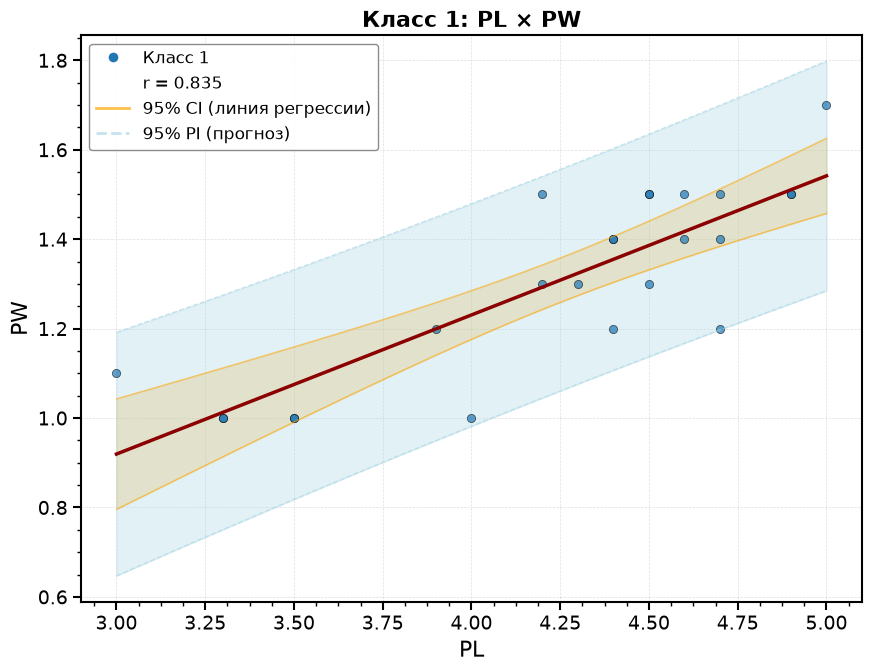

In [89]:
# ============================================================
# ПАРАМЕТРЫ ПОЛЬЗОВАТЕЛЯ ДЛЯ [2.7]
# ============================================================
SELECTED_CLASS = 1            # какой класс взять
X_FEATURE      = "PL"         # признак по оси X
Y_FEATURE      = "PW"         # признак по оси Y

SHOW_REGRESSION      = True   # линия регрессии
SHOW_CONFIDENCE_BAND = True   # доверительная полоса (где лежит истинная линия)
SHOW_PREDICTION_BAND = True   # прогнозная полоса (где появятся новые точки)
CONFIDENCE_LEVEL     = 0.95   # уровень доверия полос (0.90 / 0.95 / 0.99)


fig, ax = single_class_scatter(
    df0m,
    class_col=target,
    selected_class=SELECTED_CLASS,
    x_feature=X_FEATURE,
    y_feature=Y_FEATURE,

    show_regression=SHOW_REGRESSION,
    show_confidence_band=SHOW_CONFIDENCE_BAND,
    show_prediction_band=SHOW_PREDICTION_BAND,
    confidence_level=CONFIDENCE_LEVEL,

    fig_size=(9, 7),
    print_stats=True,

    # --- Регулируемые параметры визуализации (любые из custom_scatter) ---
    point_size=35,
    point_alpha=0.7,
    point_marker="o",
    point_colors="#1f77b4",          # один цвет для одного класса
    point_edgecolor="black",
    point_linewidth=0.5,

    correlation_color="darkred",     # линия регрессии
    correlation_width=2.5,

    confidence_band_color="orange",  # полоса CI
    confidence_band_alpha=0.25,
    confidence_band_linestyle="-",
    confidence_band_linewidth=1,

    interval_color="lightblue",      # полоса PI
    interval_alpha=0.35,
    interval_linestyle="--",
    interval_linewidth=1,

    show_grid=True,
    grid_alpha=0.25,
    show_legend=True,
    legend_loc="upper left",
    show_intervals=True,             # текст Δx на графике
)
plt.show()

Класс 0 | n = 20
Регрессия: y = 0.0780·x + 0.1184
r = 0.1443 | R² = 0.0208
Уровень доверия: 95% | линия: вкл, CI: вкл, PI: вкл


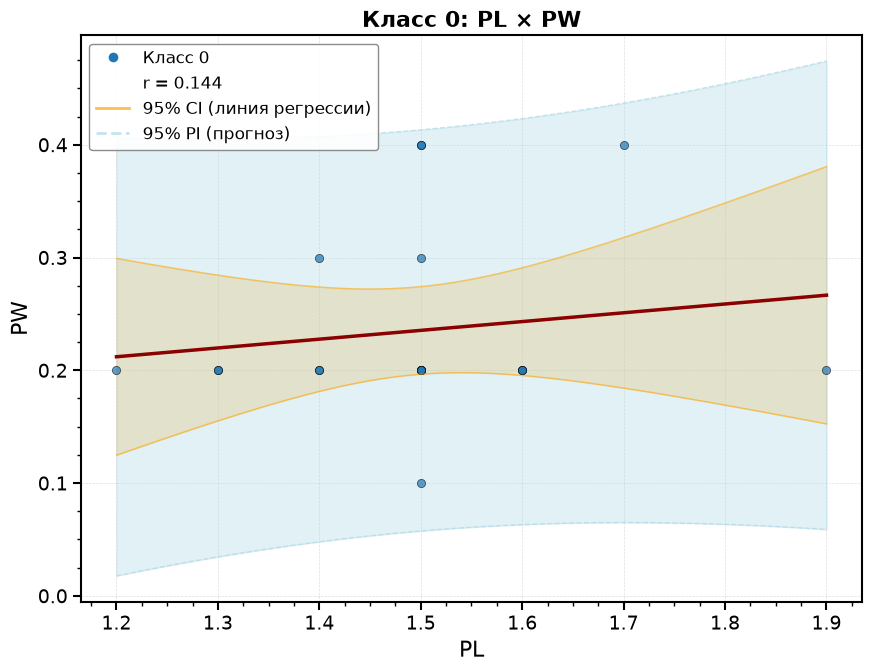

In [90]:
# ============================================================
# ПАРАМЕТРЫ ПОЛЬЗОВАТЕЛЯ ДЛЯ [2.7]
# ============================================================
SELECTED_CLASS = 0            # какой класс взять
X_FEATURE      = "PL"         # признак по оси X
Y_FEATURE      = "PW"         # признак по оси Y

SHOW_REGRESSION      = True   # линия регрессии
SHOW_CONFIDENCE_BAND = True   # доверительная полоса (где лежит истинная линия)
SHOW_PREDICTION_BAND = True   # прогнозная полоса (где появятся новые точки)
CONFIDENCE_LEVEL     = 0.95   # уровень доверия полос (0.90 / 0.95 / 0.99)


fig, ax = single_class_scatter(
    df0m,
    class_col=target,
    selected_class=SELECTED_CLASS,
    x_feature=X_FEATURE,
    y_feature=Y_FEATURE,

    show_regression=SHOW_REGRESSION,
    show_confidence_band=SHOW_CONFIDENCE_BAND,
    show_prediction_band=SHOW_PREDICTION_BAND,
    confidence_level=CONFIDENCE_LEVEL,

    fig_size=(9, 7),
    print_stats=True,

    # --- Регулируемые параметры визуализации (любые из custom_scatter) ---
    point_size=35,
    point_alpha=0.7,
    point_marker="o",
    point_colors="#1f77b4",          # один цвет для одного класса
    point_edgecolor="black",
    point_linewidth=0.5,

    correlation_color="darkred",     # линия регрессии
    correlation_width=2.5,

    confidence_band_color="orange",  # полоса CI
    confidence_band_alpha=0.25,
    confidence_band_linestyle="-",
    confidence_band_linewidth=1,

    interval_color="lightblue",      # полоса PI
    interval_alpha=0.35,
    interval_linestyle="--",
    interval_linewidth=1,

    show_grid=True,
    grid_alpha=0.25,
    show_legend=True,
    legend_loc="upper left",
    show_intervals=True,             # текст Δx на графике
)
plt.show()


### **[2.8]** Линии регрессии для каждого класса
Отдельно повторно выполнить пункт **[2.6]**, отобразив на каждом из графиков для **каждого из классов**:
- линию линейной регрессии с соответствующими **прогнозными (predictive bands)** полосами регрессий,
- которые возможно опционально **включить/отключить** перед отображением.

---

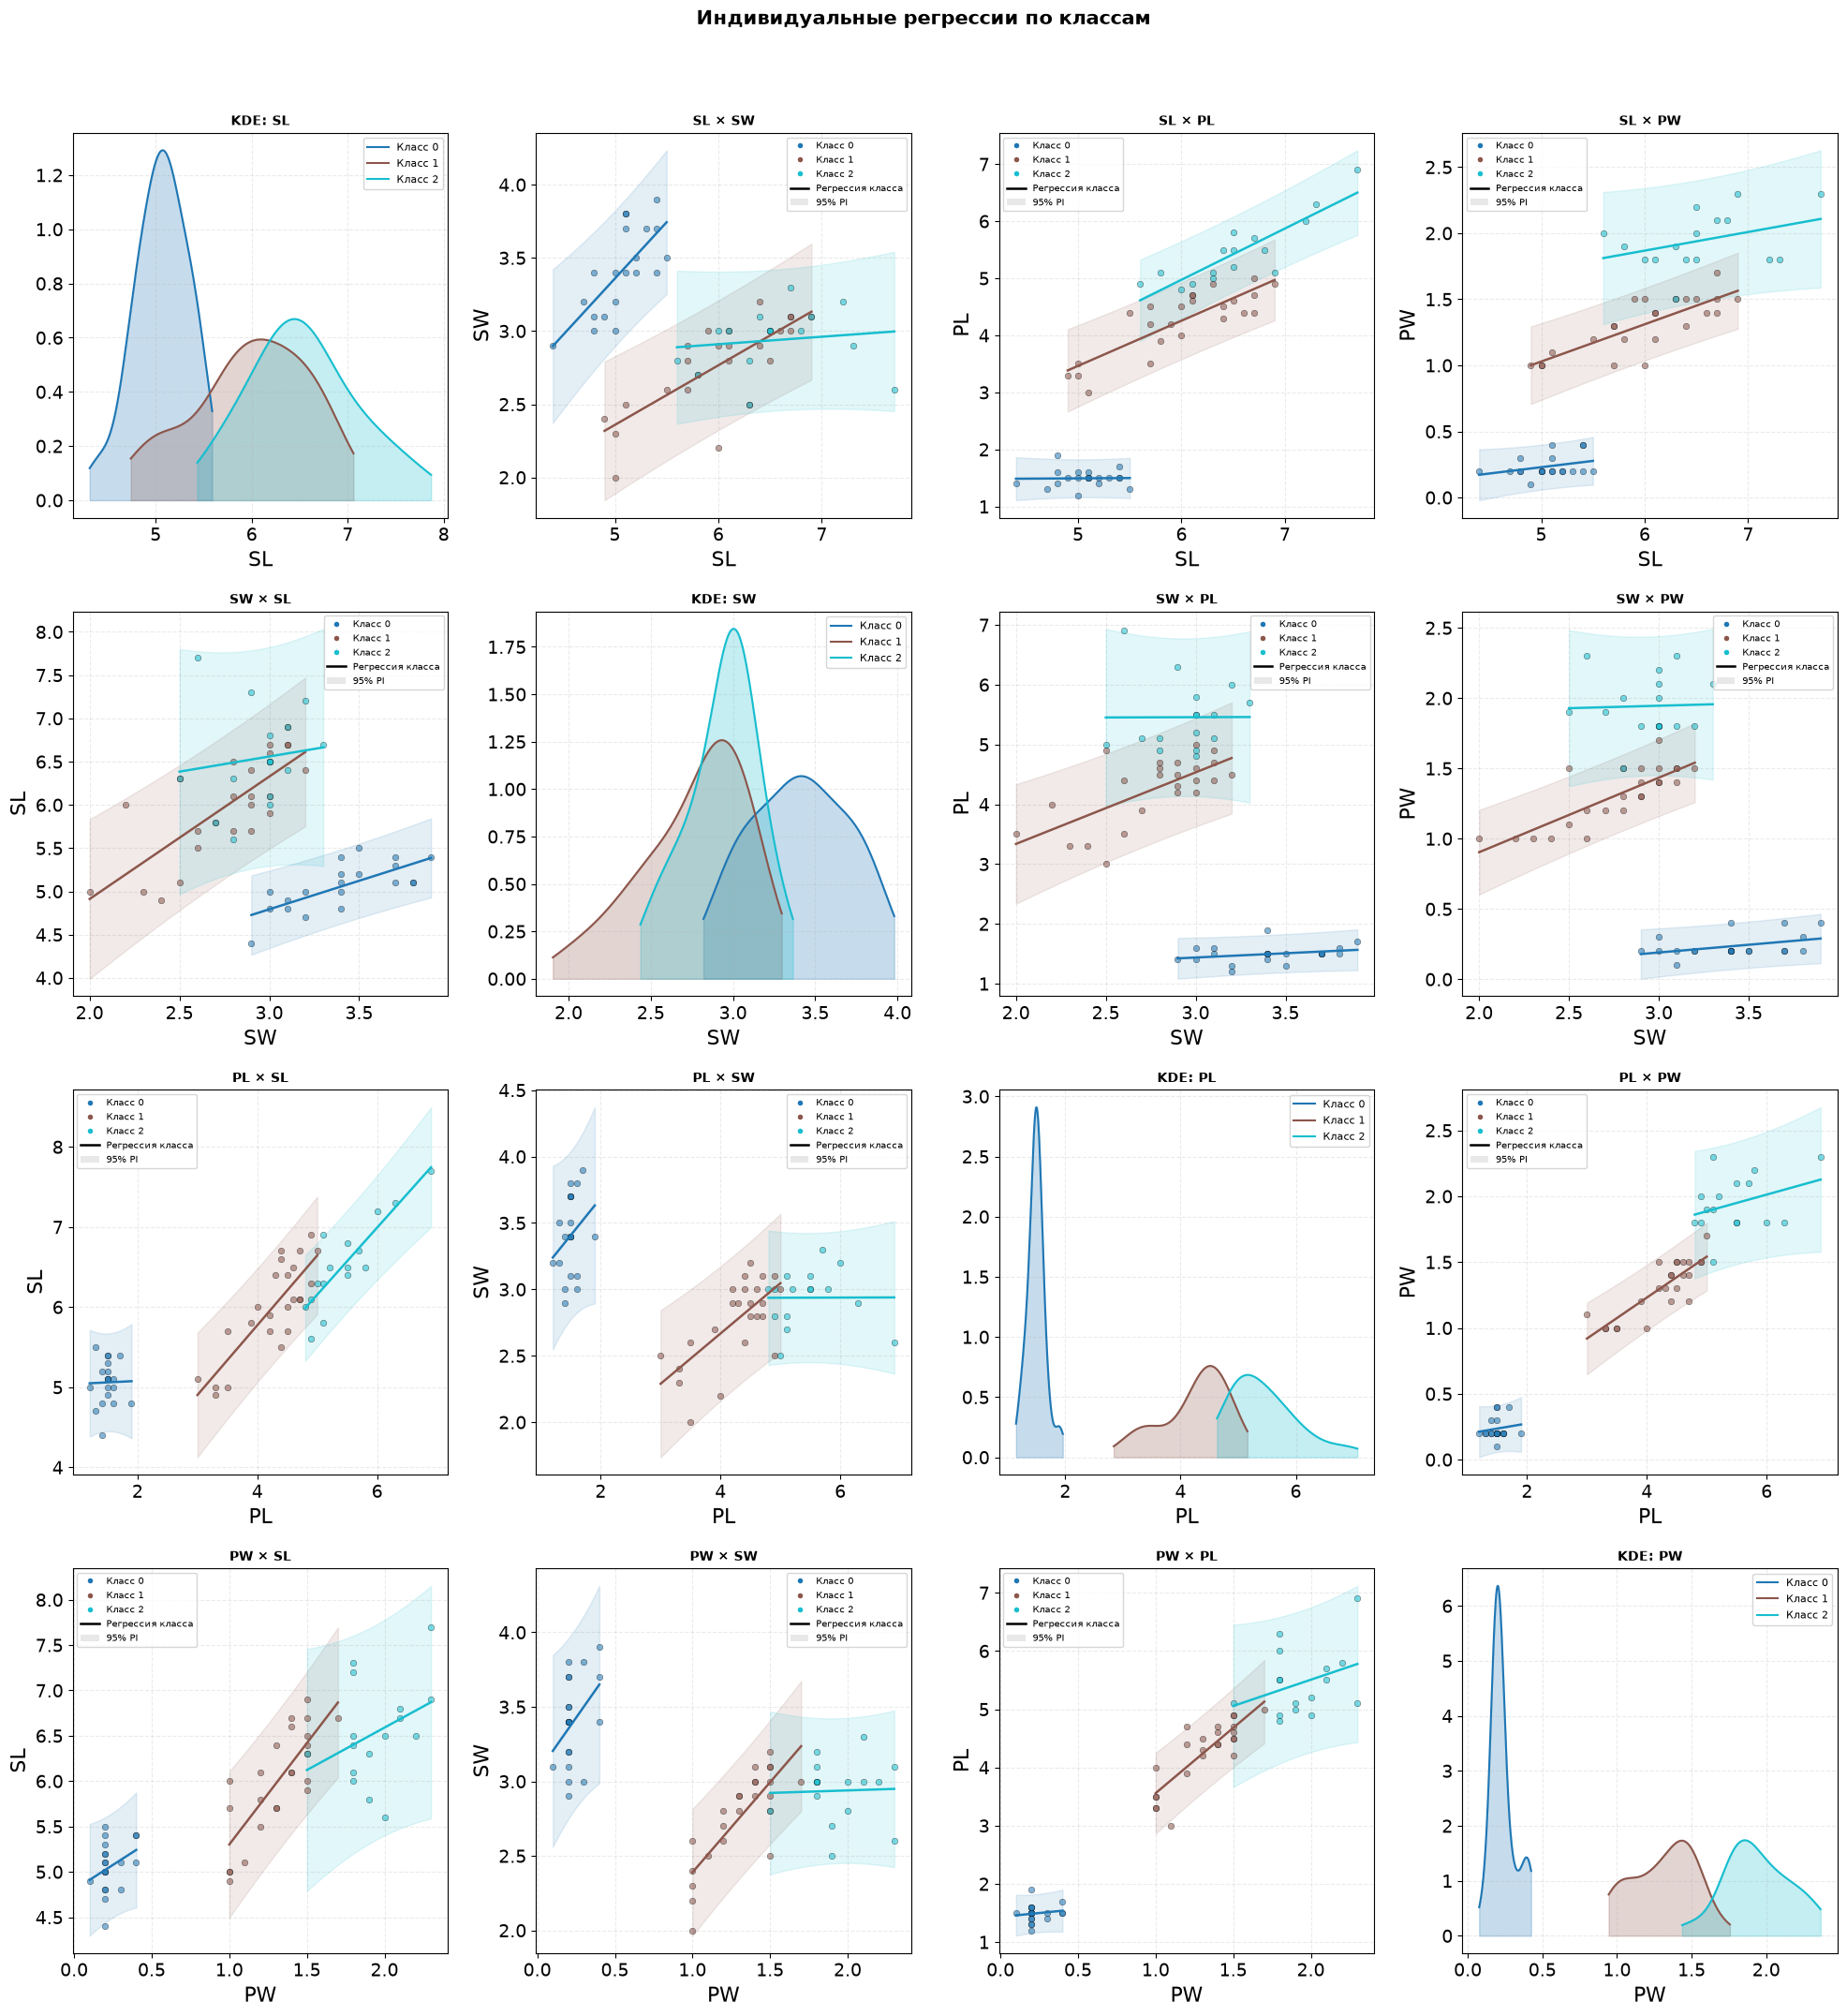

In [91]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import gaussian_kde


def plot_pair_grid_with_class_regression(
    df,
    features,
    class_col="class",
    show_reg=True,
    show_bands=True,
    conf_level=0.95,
):
    # Исключаем столбец классов из списка признаков
    features = [f for f in features if f != class_col]
    classes = sorted(df[class_col].dropna().unique())

    if not features:
        raise ValueError("Не переданы признаки для построения графиков.")
    if not classes:
        raise ValueError(f"В столбце '{class_col}' не найдены классы.")

    n_features = len(features)
    colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))
    class_color_map = dict(zip(classes, colors))

    fig, axes = plt.subplots(
        n_features,
        n_features,
        figsize=(5 * n_features, 5.5 * n_features),
        squeeze=False,
    )

    for row, x_name in enumerate(features):
        for col, y_name in enumerate(features):
            ax = axes[row, col]

            # Диагональ: распределение одного признака по классам
            if row == col:
                for cls in classes:
                    values = df.loc[
                        df[class_col] == cls, x_name
                    ].to_numpy(dtype=float)

                    values = values[np.isfinite(values)]
                    color = class_color_map[cls]

                    if len(values) > 1 and np.ptp(values) > 0:
                        try:
                            kde = gaussian_kde(values)
                            padding = np.ptp(values) * 0.08
                            grid = np.linspace(
                                values.min() - padding,
                                values.max() + padding,
                                300,
                            )
                            density = kde(grid)

                            ax.fill_between(
                                grid,
                                density,
                                color=color,
                                alpha=0.25,
                            )
                            ax.plot(
                                grid,
                                density,
                                color=color,
                                linewidth=1.5,
                                label=f"Класс {cls}",
                            )
                        except np.linalg.LinAlgError:
                            pass

                ax.set_title(f"KDE: {x_name}", fontsize=10, fontweight="bold")
                ax.set_xlabel(x_name)
                ax.grid(True, linestyle="--", alpha=0.25)
                ax.legend(fontsize=8, loc="best")

            # Вне диагонали: точки и регрессии для каждого класса
            else:
                for cls in classes:
                    color = class_color_map[cls]
                    subset = df.loc[df[class_col] == cls, [x_name, y_name]]

                    x = subset[x_name].to_numpy(dtype=float)
                    y = subset[y_name].to_numpy(dtype=float)

                    valid = np.isfinite(x) & np.isfinite(y)
                    x = x[valid]
                    y = y[valid]

                    ax.scatter(
                        x,
                        y,
                        s=22,
                        alpha=0.55,
                        color=color,
                        edgecolor="black",
                        linewidth=0.4,
                        zorder=3,
                    )

                    # Для регрессии нужны как минимум две точки
                    # с различающимися значениями X
                    if (
                        show_reg
                        and len(x) >= 2
                        and np.ptp(x) > 0
                    ):
                        regression = stats.linregress(x, y)
                        slope = regression.slope
                        intercept = regression.intercept

                        x_line = np.linspace(x.min(), x.max(), 150)
                        y_line = slope * x_line + intercept

                        ax.plot(
                            x_line,
                            y_line,
                            color=color,
                            linewidth=1.8,
                            zorder=4,
                        )

                        # Прогнозная полоса для новых наблюдений
                        if show_bands and len(x) > 2:
                            n = len(x)
                            residuals = y - (slope * x + intercept)
                            residual_std = np.sqrt(
                                np.sum(residuals**2) / (n - 2)
                            )

                            x_mean = np.mean(x)
                            ss_x = np.sum((x - x_mean) ** 2)

                            if ss_x > 0:
                                se_prediction = residual_std * np.sqrt(
                                    1
                                    + 1 / n
                                    + (x_line - x_mean) ** 2 / ss_x
                                )

                                t_critical = stats.t.ppf(
                                    (1 + conf_level) / 2,
                                    df=n - 2,
                                )

                                ax.fill_between(
                                    x_line,
                                    y_line - t_critical * se_prediction,
                                    y_line + t_critical * se_prediction,
                                    color=color,
                                    alpha=0.12,
                                    zorder=2,
                                )

                ax.set_title(
                    f"{x_name} × {y_name}",
                    fontsize=10,
                    fontweight="bold",
                )
                ax.set_xlabel(x_name)
                ax.set_ylabel(y_name)
                ax.grid(True, linestyle="--", alpha=0.25)

                # Легенда показывает классы и общие обозначения линий/полос
                handles = [
                    Line2D(
                        [0], [0],
                        marker="o",
                        linestyle="none",
                        markerfacecolor=class_color_map[cls],
                        markeredgecolor="white",
                        markersize=5,
                        label=f"Класс {cls}",
                    )
                    for cls in classes
                ]

                handles.extend([
                    Line2D(
                        [0], [0],
                        color="black",
                        linewidth=1.8,
                        label="Регрессия класса",
                    ),
                    Patch(
                        facecolor="gray",
                        alpha=0.18,
                        label=f"{conf_level:.0%} PI",
                    ),
                ])

                ax.legend(handles=handles, fontsize=7, loc="best")

    fig.suptitle(
        "Индивидуальные регрессии по классам",
        fontsize=15,
        fontweight="bold",
    )

    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


plot_pair_grid_with_class_regression(
    df=df0m,
    features=features,
    class_col=target,
    show_reg=True,
    show_bands=True,
    conf_level=0.95,
)


### **[2.9]** Формулы и критерии значимости
Вывести формулы **каждой оцененной линейной регрессии** вместе со значениями:
- критерия **R²**;
- критериев **Вальда**, **LR** и **score** (для каждого вывести **F-критерий**, его **степени свободы** и соответствующий **p-критерий**).

---

In [92]:
from scipy import stats

rows = []

df1 = 1  # одна проверяемая гипотеза: beta = 0
features = [f for f in features if f != 'Species']
pairs = [(x, y) for x in features for y in features if x != y]

for x_name, y_name in pairs:
    x = df0m[x_name].to_numpy(dtype=float)
    y = df0m[y_name].to_numpy(dtype=float)

    n = len(y)
    df2 = n - 2

    # Центрирование
    x_bar = x.mean()
    y_bar = y.mean()

    xc = x - x_bar
    yc = y - y_bar

    # Суммы квадратов и cross-product
    sxx = float(xc @ xc)
    syy = float(yc @ yc)
    sxy = float(xc @ yc)

    # OЦМ-оценки
    beta = sxy / sxx
    alpha = y_bar - beta * x_bar

    # R^2 = corr(x, y)^2
    r2 = (sxy * sxy) / (sxx * syy)

    # Численная защита от r2 == 1
    r2 = float(np.clip(r2, 0.0, 1.0 - 1e-15))

    # SSE, MSE, стандартная ошибка наклона
    sse = syy * (1.0 - r2)
    mse = sse / df2
    se_beta = np.sqrt(mse / sxx)

    # Исходные критерии как chi-square с 1 df
    wald_chi2 = float((beta / se_beta) ** 2)
    lr_chi2 = float(-n * np.log1p(-r2))
    score_chi2 = float(n * r2)

    # F-версии критериев
    F_wald = wald_chi2
    F_lr = float(df2 * (np.exp(lr_chi2 / n) - 1.0))
    F_score = float(df2 * score_chi2 / (n - score_chi2))

    # p-values по F-распределению
    p_wald = float(stats.f.sf(F_wald, df1, df2))
    p_lr = float(stats.f.sf(F_lr, df1, df2))
    p_score = float(stats.f.sf(F_score, df1, df2))

    rows.append({
        "Пара": f"{x_name} -> {y_name}",
        "Формула регрессии": f"{y_name} = {alpha:.4f} + {beta:.4f} {x_name}",
        "R2": r2,

        "Wald chi2": wald_chi2,
        "F_Wald": F_wald,
        "df_Wald": f"({df1}, {df2})",
        "p_Wald": p_wald,

        "LR chi2": lr_chi2,
        "F_LR": F_lr,
        "df_LR": f"({df1}, {df2})",
        "p_LR": p_lr,

        "Score chi2": score_chi2,
        "F_Score": F_score,
        "df_Score": f"({df1}, {df2})",
        "p_Score": p_score,
    })

from IPython.display import display

results = pd.DataFrame(rows)

# Формируем компактную таблицу
summary = results[
    [
        "Формула регрессии", "R2",
        "F_Wald", "df_Wald", "p_Wald",
        "F_LR", "df_LR", "p_LR",
        "F_Score", "df_Score", "p_Score"
    ]
].copy()

# Группируем столбцы по критериям
summary.columns = pd.MultiIndex.from_tuples([
    ("Регрессия", "Формула"),
    ("Качество", "R²"),
    ("Wald", "F"),
    ("Wald", "df"),
    ("Wald", "p-value"),
    ("LR", "F"),
    ("LR", "df"),
    ("LR", "p-value"),
    ("Score", "F"),
    ("Score", "df"),
    ("Score", "p-value")
])

# Красивое оформление
display(
    summary.style
    .format({
        ("Качество", "R²"): "{:.3f}",
        ("Wald", "F"): "{:.3f}",
        ("Wald", "p-value"): "{:.4g}",
        ("LR", "F"): "{:.3f}",
        ("LR", "p-value"): "{:.4g}",
        ("Score", "F"): "{:.3f}",
        ("Score", "p-value"): "{:.4g}"
    })
    .background_gradient(
        subset=[("Качество", "R²")],
        cmap="Blues"
    )
    .map(
        lambda v: "color: green; font-weight: bold" if v < 0.05
        else "color: red",
        subset=[
            ("Wald", "p-value"),
            ("LR", "p-value"),
            ("Score", "p-value")
        ]
    )
    .set_caption("Линейные регрессии и критерии значимости (α = 0.05)")
    .hide(axis="index")
)


### **[2.10]** Raincloud plot + boxplot
Визуализировать **один количественный признак**, выбираемый пользователем, для каждого из классов:
- в виде **raincloud plot with jittering**;
- рядом с которым в виде **boxplot** отображены:
  - медианы,
  - межквартильные размахи (IQR),
  - доверительные интервалы.

---

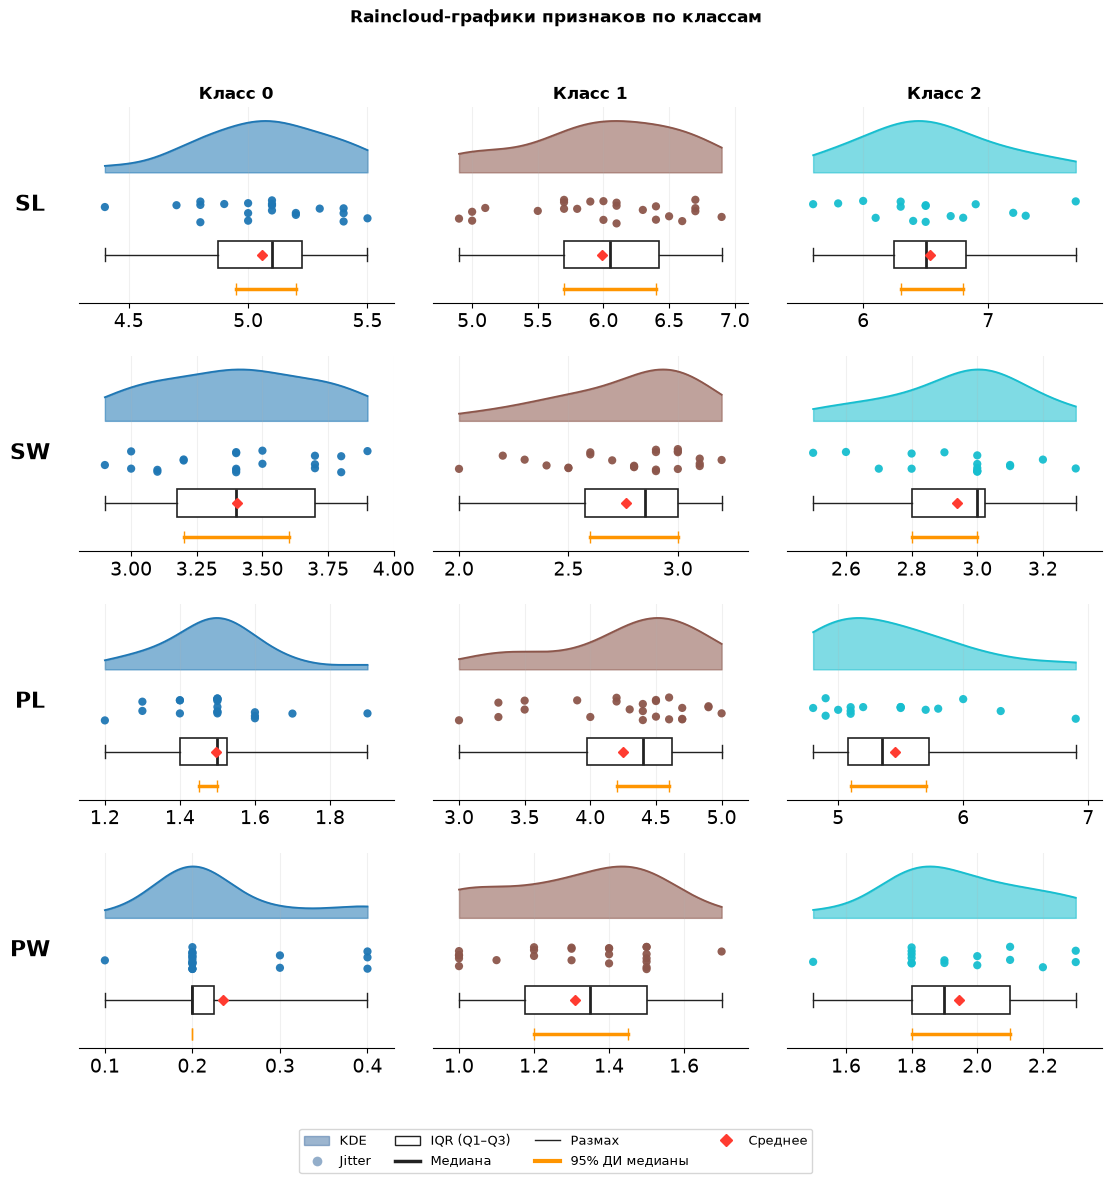

In [102]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def _adaptive_style(n):
    if n <= 30:
        return 0.95, 35
    if n <= 100:
        return 0.75, 30
    if n <= 500:
        return 0.50, 25
    if n <= 2000:
        return 0.30, 20
    if n <= 10000:
        return 0.20, 15
    return 0.10, 10


def _raincloud_legend(color="#4C78A8"):
    """Одна общая легенда для всей панели."""
    return [
        Patch(facecolor=color, edgecolor=color, alpha=0.55, label="KDE"),
        Line2D(
            [0], [0], marker="o", color="none",
            markerfacecolor=color, markeredgecolor="none",
            markersize=7, alpha=0.6, label="Jitter"
        ),
        Patch(
            facecolor="white", edgecolor="#222222",
            label="IQR (Q1–Q3)"
        ),
        Line2D(
            [0], [0], color="#222222",
            linewidth=2.5, label="Медиана"
        ),
        Line2D(
            [0], [0], color="#222222",
            linewidth=1, label="Размах"
        ),
        Line2D(
            [0], [0], color="#FF9500",
            linewidth=3, label="95% ДИ медианы"
        ),
        Line2D(
            [0], [0], marker="D", color="none",
            markerfacecolor="#FF3B30", markeredgecolor="#FF3B30",
            markersize=6, label="Среднее"
        ),
    ]


def plot_raincloud_cell(
    ax,
    values,
    color,
    rng,
    whis=(0, 100),
    show_mean=True,
):
    """Рисует raincloud и boxplot для одного признака и одного класса."""
    x = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy()
    n = x.size

    if n == 0:
        ax.text(
            0.5, 0.5, "Нет данных",
            transform=ax.transAxes,
            ha="center", va="center"
        )
        ax.set_yticks([])
        return

    scatter_alpha, scatter_size = _adaptive_style(n)

    # KDE
    if n > 1 and np.ptp(x) > 0:
        kde = gaussian_kde(x)
        xx = np.linspace(x.min(), x.max(), 400)
        yy = kde(xx)
        yy = yy / yy.max() * 0.30

        cloud_y = 0.20
        ax.fill_between(
            xx, cloud_y, cloud_y + yy,
            color=color, alpha=0.55, zorder=1
        )
        ax.plot(
            xx, cloud_y + yy,
            color=color, linewidth=1.3, zorder=2
        )

    # Jitter
    y_jitter = rng.uniform(-0.07, 0.07, size=n)
    ax.scatter(
        x, y_jitter - 0.03,
        color=color,
        alpha=scatter_alpha,
        s=scatter_size,
        edgecolors="none",
        zorder=3,
    )

    # Boxplot
    ax.boxplot(
        x,
        orientation="horizontal",
        positions=[-0.28],
        widths=0.16,
        whis=whis,
        showfliers=False,
        showmeans=show_mean,
        patch_artist=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "#FF3B30",
            "markeredgecolor": "#FF3B30",
            "markersize": 5,
        },
        medianprops={
            "color": "#222222",
            "linewidth": 2,
        },
        boxprops={
            "facecolor": "white",
            "edgecolor": "#222222",
            "linewidth": 1.2,
        },
        whiskerprops={
            "color": "#222222",
            "linewidth": 1,
        },
        capprops={
            "color": "#222222",
            "linewidth": 1,
        },
    )

    # Bootstrap-доверительный интервал медианы
    if n > 1:
        bootstrap_medians = np.array([
            np.median(rng.choice(x, size=n, replace=True))
            for _ in range(1000)
        ])
        ci_low, ci_high = np.percentile(bootstrap_medians, [2.5, 97.5])

        ax.plot(
            [ci_low, ci_high], [-0.48, -0.48],
            color="#FF9500",
            linewidth=2.5,
            marker="|",
            markersize=8,
            zorder=4,
        )
    # Независимый масштаб и небольшой отступ для каждой ячейки
    xmin, xmax = np.min(x), np.max(x)
    span = xmax - xmin
    padding = span * 0.10 if span > 0 else max(abs(xmin) * 0.05, 0.1)
    ax.set_xlim(xmin - padding, xmax + padding)

    ax.set_ylim(-0.56, 0.58)
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.18)
    ax.spines[["left", "right", "top"]].set_visible(False)


# ------------------------------------------------------------
# Настройки панели
# ------------------------------------------------------------

target_col = target  # в ноутбуке target — столбец с классами

# Все числовые признаки, кроме столбца класса.
# При необходимости замените на явный список, например:
# features = ["SL", "SW", "PL", "PW"]
features = [
    col for col in df0m.select_dtypes(include=np.number).columns
    if col != target_col
]

classes = sorted(df0m[target_col].dropna().unique())

if not features:
    raise ValueError("В датасете не найдены числовые признаки.")
if not classes:
    raise ValueError("В столбце классов не найдены значения.")

class_colors = plt.cm.tab10(
    np.linspace(0, 1, len(classes))
)

# N строк = число признаков; M столбцов = число классов
fig, axes = plt.subplots(
    nrows=len(features),
    ncols=len(classes),
    figsize=(3.8 * len(classes), 3 * len(features)),
    squeeze=False,
    sharex=False,
)

rng = np.random.default_rng(42)

for row, feature in enumerate(features):
    for col, class_value in enumerate(classes):
        ax = axes[row, col]

        values = df0m.loc[
            df0m[target_col] == class_value,
            feature
        ]

        plot_raincloud_cell(
            ax=ax,
            values=values,
            color=class_colors[col],
            rng=rng,
            whis=(0, 100),
            show_mean=True,
        )

        if row == 0:
            ax.set_title(
                f"Класс {class_value}",
                fontsize=12,
                fontweight="bold",
            )

        if col == 0:
            ax.set_ylabel(
                feature,
                rotation=0,
                labelpad=35,
                va="center",
                fontweight="bold",
            )

fig.suptitle(
    "Raincloud-графики признаков по классам",
    fontsize=12,
    fontweight="bold",
)

fig.legend(
    handles=_raincloud_legend(),
    loc="lower center",
    ncol=4,
    frameon=True,
    fontsize=9,
    bbox_to_anchor=(0.5, 0.005),
)

plt.tight_layout(rect=(0, 0.07, 1, 0.97))
plt.show()



### **[2.11]** Дисперсионный анализ (ANOVA)
Выполнить дисперсионный анализ (ANOVA) по **одному из признаков**, выбираемому пользователем:
- рассчитать **общий F-критерий**, его **степени свободы `df1` и `df2`** и соответствующий ему **p-критерий** для **всех классов одновременно**;
- а также **для каждой пары классов**.

---

In [94]:
import numpy as np
import pandas as pd
from scipy import stats
from itertools import combinations
from IPython.display import display, Markdown

# ============================================================
# НАСТРОЙКИ
# ============================================================

ANOVA_FEATURE = "PL"   # Признак для ANOVA
TARGET_COL = "Species" # Столбец с классами
ALPHA = 0.05           # Уровень значимости


# ============================================================
# ПОДГОТОВКА ДАННЫХ
# ============================================================

def _prepare_anova_data(df, feature, target):
    if feature not in df.columns:
        raise ValueError(f"Признак '{feature}' отсутствует в DataFrame.")

    if target not in df.columns:
        raise ValueError(f"Столбец классов '{target}' отсутствует в DataFrame.")

    data = df[[feature, target]].copy()

    # Преобразуем признак в числовой формат
    data[feature] = pd.to_numeric(data[feature], errors="coerce")

    # Убираем пропущенные и бесконечные значения
    data = data.dropna(subset=[feature, target])
    data = data[np.isfinite(data[feature])].copy()

    classes = np.sort(pd.unique(data[target]))

    return data, classes


# ============================================================
# РАСЧЁТ ОДНОФАКТОРНОГО ANOVA
# ============================================================

def _anova_stats(groups):
    clean_groups = []

    for group in groups:
        arr = np.asarray(group, dtype=float).ravel()
        arr = arr[np.isfinite(arr)]
        clean_groups.append(arr)

    # Пустые группы исключаем из расчёта
    clean_groups = [g for g in clean_groups if len(g) > 0]

    N = sum(len(g) for g in clean_groups)
    k = len(clean_groups)

    result = {
        "N": N,
        "k": k,
        "df1": np.nan,
        "df2": np.nan,
        "SS_between": np.nan,
        "SS_within": np.nan,
        "MS_between": np.nan,
        "MS_within": np.nan,
        "F": np.nan,
        "p_value": np.nan,
    }

    # Необходимо минимум две группы и больше наблюдений, чем групп
    if k < 2 or N <= k:
        return result

    all_values = np.concatenate(clean_groups)
    grand_mean = float(all_values.mean())

    ss_between = 0.0
    ss_within = 0.0

    for group in clean_groups:
        group_mean = float(group.mean())

        ss_between += len(group) * (group_mean - grand_mean) ** 2
        ss_within += float(np.sum((group - group_mean) ** 2))

    df1 = k - 1
    df2 = N - k

    ms_between = ss_between / df1
    ms_within = ss_within / df2

    # Защита от деления на ноль
    if np.isclose(ms_within, 0.0, rtol=0.0, atol=1e-15):
        if np.isclose(ms_between, 0.0, rtol=0.0, atol=1e-15):
            F = np.nan
            p_value = np.nan
        else:
            F = np.inf
            p_value = 0.0
    else:
        F = ms_between / ms_within
        p_value = float(stats.f.sf(F, df1, df2))

    if np.isfinite(p_value):
        p_value = min(max(p_value, 0.0), 1.0)

    result.update({
        "df1": df1,
        "df2": df2,
        "SS_between": ss_between,
        "SS_within": ss_within,
        "MS_between": ms_between,
        "MS_within": ms_within,
        "F": F,
        "p_value": p_value,
    })

    return result


# ============================================================
# ПРОВЕРКА И ПОДГОТОВКА ДАННЫХ
# ============================================================

available_features = [
    c for c in df0m.columns
    if c != TARGET_COL
    and pd.api.types.is_numeric_dtype(df0m[c])
]

print("Доступные числовые признаки:", available_features)
print(f"Выбранный признак для ANOVA: {ANOVA_FEATURE}")
print("-" * 70)

if ANOVA_FEATURE not in available_features:
    raise ValueError(
        f"Признак '{ANOVA_FEATURE}' не найден среди доступных "
        f"числовых признаков: {available_features}"
    )

anova_data, anova_classes = _prepare_anova_data(
    df=df0m,
    feature=ANOVA_FEATURE,
    target=TARGET_COL,
)

if len(anova_classes) < 2:
    raise ValueError(
        "Для проведения ANOVA необходимо как минимум два класса."
    )

# Данные по каждому классу
overall_groups = [
    anova_data.loc[
        anova_data[TARGET_COL] == c,
        ANOVA_FEATURE
    ].to_numpy()
    for c in anova_classes
]

# Общий ANOVA
overall_stats = _anova_stats(overall_groups)


# ============================================================
# ТАБЛИЦА ОБЩЕГО ANOVA
# ============================================================

anova_table = pd.DataFrame({
    "Источник вариации": [
        "Между классами",
        "Внутри классов",
        "Итого",
    ],
    "SS": [
        overall_stats["SS_between"],
        overall_stats["SS_within"],
        (
            overall_stats["SS_between"] + overall_stats["SS_within"]
            if np.isfinite(overall_stats["SS_between"])
            and np.isfinite(overall_stats["SS_within"])
            else np.nan
        ),
    ],
    "df": [
        overall_stats["df1"],
        overall_stats["df2"],
        (
            overall_stats["N"] - 1
            if np.isfinite(overall_stats["df1"])
            and np.isfinite(overall_stats["df2"])
            else np.nan
        ),
    ],
    "MS": [
        overall_stats["MS_between"],
        overall_stats["MS_within"],
        np.nan,
    ],
    "F": [
        overall_stats["F"],
        np.nan,
        np.nan,
    ],
    "p_value": [
        overall_stats["p_value"],
        np.nan,
        np.nan,
    ],
})


# ============================================================
# ПОПАРНЫЕ СРАВНЕНИЯ КЛАССОВ
# ============================================================

pairwise_results = []

for class_a, class_b in combinations(anova_classes, 2):

    group_a = anova_data.loc[
        anova_data[TARGET_COL] == class_a,
        ANOVA_FEATURE
    ].to_numpy()

    group_b = anova_data.loc[
        anova_data[TARGET_COL] == class_b,
        ANOVA_FEATURE
    ].to_numpy()

    pair_stats = _anova_stats([group_a, group_b])

    mean_a = float(np.mean(group_a)) if len(group_a) else np.nan
    mean_b = float(np.mean(group_b)) if len(group_b) else np.nan

    p_value = pair_stats["p_value"]

    pairwise_results.append({
        "class_a": class_a,
        "class_b": class_b,
        "n_a": len(group_a),
        "n_b": len(group_b),
        "mean_a": mean_a,
        "mean_b": mean_b,
        "F": pair_stats["F"],
        "df1": pair_stats["df1"],
        "df2": pair_stats["df2"],
        "p_value": p_value,
        "significant": (
            bool(p_value < ALPHA)
            if np.isfinite(p_value)
            else False
        ),
    })

pairwise_df = pd.DataFrame(pairwise_results)


# ============================================================
# ФУНКЦИИ ОФОРМЛЕНИЯ
# ============================================================

def style_p_value(value):
    if pd.isna(value):
        return ""

    if value < ALPHA:
        return "color: #198754; font-weight: bold"

    return "color: #DC3545"


def style_significance(value):
    if pd.isna(value):
        return ""

    if value:
        return (
            "background-color: #d1e7dd; "
            "color: #0f5132; font-weight: bold"
        )

    return "background-color: #f8d7da; color: #842029"


# ============================================================
# 1. ОБЩИЙ ANOVA
# ============================================================

display(Markdown(
    f"# Результаты дисперсионного анализа (ANOVA)\n"
    f"**Признак:** `{ANOVA_FEATURE}`  \n"
    f"**Уровень значимости:** α = {ALPHA}  \n"
    f"**Количество классов:** {overall_stats['k']}  \n"
    f"**Количество наблюдений:** {overall_stats['N']}"
))

display(Markdown("## 1. Таблица дисперсионного анализа"))

anova_table_view = anova_table.rename(
    columns={"p_value": "p-value"}
)

display(
    anova_table_view.style
    .format({
        "SS": "{:.4f}",
        "MS": "{:.4f}",
        "F": "{:.4f}",
        "p-value": "{:.4g}",
    }, na_rep="—")
    .map(style_p_value, subset=["p-value"])
    .set_caption("Таблица 1. Результаты общего ANOVA")
    .hide(axis="index")
)


# ============================================================
# 2. СВОДКА ОСНОВНЫХ РЕЗУЛЬТАТОВ
# ============================================================

overall_p = overall_stats["p_value"]

if np.isfinite(overall_p):
    if overall_p < ALPHA:
        overall_conclusion = "Есть значимые различия"
    else:
        overall_conclusion = "Значимые различия не обнаружены"
else:
    overall_conclusion = "Результат не определён"

overall_view = pd.DataFrame([{
    "Признак": ANOVA_FEATURE,
    "F-критерий": overall_stats["F"],
    "df1": overall_stats["df1"],
    "df2": overall_stats["df2"],
    "p-value": overall_p,
    "Результат": overall_conclusion,
}])

display(
    overall_view.style
    .format({
        "F-критерий": "{:.4f}",
        "p-value": "{:.4g}",
    }, na_rep="—")
    .map(style_p_value, subset=["p-value"])
    .set_caption("Таблица 2. Основные результаты проверки")
    .hide(axis="index")
)


# ============================================================
# 3. ИНТЕРПРЕТАЦИЯ ОБЩЕГО ANOVA
# ============================================================

display(Markdown("## 2. Интерпретация общего теста"))

if np.isfinite(overall_p):

    if overall_p < ALPHA:
        display(Markdown(
            f"🟢 **Обнаружены статистически значимые различия.**\n\n"
            f"**F({int(overall_stats['df1'])}, "
            f"{int(overall_stats['df2'])}) = "
            f"{overall_stats['F']:.4f}, "
            f"p = {overall_p:.4g}.**\n\n"
            f"Поскольку p-value < α = {ALPHA}, нулевая гипотеза "
            f"о равенстве средних значений признака "
            f"`{ANOVA_FEATURE}` во всех классах отвергается. "
            f"По крайней мере среднее значение одного класса "
            f"отличается от среднего значения другого."
        ))

    else:
        display(Markdown(
            f"🔴 **Статистически значимые различия не обнаружены.**\n\n"
            f"**F({int(overall_stats['df1'])}, "
            f"{int(overall_stats['df2'])}) = "
            f"{overall_stats['F']:.4f}, "
            f"p = {overall_p:.4g}.**\n\n"
            f"Поскольку p-value ≥ α = {ALPHA}, нет достаточных "
            f"оснований отвергнуть нулевую гипотезу о равенстве "
            f"средних значений признака `{ANOVA_FEATURE}` между классами."
        ))

else:
    display(Markdown(
        "⚠️ **Общий ANOVA не удалось корректно вычислить.** "
        "Проверьте количество наблюдений и значения признака."
    ))


# ============================================================
# 4. ПОПАРНЫЕ СРАВНЕНИЯ КЛАССОВ
# ============================================================

display(Markdown(
    f"## 3. Попарные сравнения классов\n\n"
    f"Для каждой пары классов проверяется гипотеза о равенстве "
    f"средних значений признака `{ANOVA_FEATURE}`."
))

if pairwise_df.empty:

    display(Markdown("Попарных сравнений нет."))

else:

    pairwise_view = pairwise_df[[
        "class_a",
        "class_b",
        "n_a",
        "n_b",
        "mean_a",
        "mean_b",
        "F",
        "df1",
        "df2",
        "p_value",
        "significant",
    ]].copy()

    pairwise_view.columns = [
        "Класс 1",
        "Класс 2",
        "N₁",
        "N₂",
        "Среднее 1",
        "Среднее 2",
        "F-критерий",
        "df1",
        "df2",
        "p-value",
        "Значимость",
    ]

    pairwise_view["Значимость"] = pairwise_view["Значимость"].map({
        True: "Значимо",
        False: "Не значимо",
    })

    display(
        pairwise_view.style
        .format({
            "Среднее 1": "{:.4f}",
            "Среднее 2": "{:.4f}",
            "F-критерий": "{:.4f}",
            "p-value": "{:.4g}",
        }, na_rep="—")
        .map(style_p_value, subset=["p-value"])
        .map(
            lambda value: (
                "background-color: #d1e7dd; "
                "color: #0f5132; font-weight: bold"
                if value == "Значимо"
                else (
                    "background-color: #f8d7da; color: #842029"
                    if value == "Не значимо"
                    else ""
                )
            ),
            subset=["Значимость"],
        )
        .set_caption("Таблица 3. Результаты попарных сравнений")
        .hide(axis="index")
    )

    # --------------------------------------------------------
    # Интерпретация каждой пары
    # --------------------------------------------------------

    display(Markdown("### Интерпретация попарных сравнений"))

    for _, row in pairwise_df.iterrows():

        p = row["p_value"]

        if not np.isfinite(p):
            display(Markdown(
                f"- **Класс {row['class_a']} vs класс "
                f"{row['class_b']}:** результат не определён."
            ))
            continue

        if p < ALPHA:
            status = "🟢 различия статистически значимы"
        else:
            status = "🔴 значимые различия не обнаружены"

        display(Markdown(
            f"- **Класс {row['class_a']} vs класс "
            f"{row['class_b']}:** "
            f"F({int(row['df1'])}, {int(row['df2'])}) = "
            f"{row['F']:.4f}, p = {p:.4g} — {status}."
        ))


# ============================================================
# 5. ИТОГОВЫЙ ВЫВОД
# ============================================================

display(Markdown("## 4. Итоговый вывод"))

if np.isfinite(overall_p) and overall_p < ALPHA:

    if not pairwise_df.empty:

        significant_pairs = pairwise_df[
            pairwise_df["p_value"].notna()
            & (pairwise_df["p_value"] < ALPHA)
        ]

        if not significant_pairs.empty:

            pair_names = [
                f"{row['class_a']}–{row['class_b']}"
                for _, row in significant_pairs.iterrows()
            ]

            display(Markdown(
                f"Для признака **`{ANOVA_FEATURE}`** общий ANOVA "
                f"выявил статистически значимые различия между классами "
                f"(p = {overall_p:.4g} < {ALPHA}).\n\n"
                f"При попарных сравнениях значимые различия обнаружены "
                f"для следующих пар: **{', '.join(pair_names)}**.\n\n"
                f"Таким образом, гипотеза о равенстве средних значений "
                f"признака во всех классах отвергается."
            ))

        else:

            display(Markdown(
                f"Общий ANOVA выявил статистически значимые различия "
                f"между классами (p = {overall_p:.4g}), однако "
                f"в попарных сравнениях при α = {ALPHA} значимые "
                f"различия не обнаружены."
            ))

    else:

        display(Markdown(
            f"Общий ANOVA выявил статистически значимые различия "
            f"между классами для признака `{ANOVA_FEATURE}`. "
            f"Попарные сравнения не проводились."
        ))

elif np.isfinite(overall_p):

    display(Markdown(
        f"Для признака **`{ANOVA_FEATURE}`** общий ANOVA не выявил "
        f"статистически значимых различий между средними значениями "
        f"классов при α = {ALPHA} (p = {overall_p:.4g}).\n\n"
        f"Нулевая гипотеза о равенстве средних значений не отвергается."
    ))

else:

    display(Markdown(
        "По имеющимся данным не удалось сформулировать итоговый "
        "вывод по общему ANOVA. Проверьте данные и количество "
        "наблюдений в каждом классе."
    ))

Доступные числовые признаки: ['SL', 'SW', 'PL', 'PW']
Выбранный признак для ANOVA: PL
----------------------------------------------------------------------


# Результаты дисперсионного анализа (ANOVA)
**Признак:** `PL`  
**Уровень значимости:** α = 0.05  
**Количество классов:** 3  
**Количество наблюдений:** 60

## 1. Таблица дисперсионного анализа

Источник вариации,SS,df,MS,F,p-value
Между классами,153.7205,2,76.8602,347.4563,1.179e-32
Внутри классов,12.6089,57,0.2212,—,—
Итого,166.3293,59,—,—,—


Признак,F-критерий,df1,df2,p-value,Результат
PL,347.4563,2,57,1.179e-32,Есть значимые различия


## 2. Интерпретация общего теста

... (5 outputs left out)

- **Класс 0 vs класс 2:** F(1, 34) = 876.7665, p = 7.346e-26 — 🟢 различия статистически значимы.

- **Класс 1 vs класс 2:** F(1, 38) = 43.5817, p = 8.549e-08 — 🟢 различия статистически значимы.

## 4. Итоговый вывод

Для признака **`PL`** общий ANOVA выявил статистически значимые различия между классами (p = 1.179e-32 < 0.05).

При попарных сравнениях значимые различия обнаружены для следующих пар: **0–1, 0–2, 1–2**.

Таким образом, гипотеза о равенстве средних значений признака во всех классах отвергается.

### **[2.12\*\*]** Генерация случайного гауссова датасета
Используя функцию `multivariate_normal` из `numpy`, отдельным блоком ipynb:
- сгенерировать и визуализировать датасет `dfG` **случайной формы распределения** (за счёт матрицы ковариаций гауссиана, без вывода цифр);
- в котором есть **два количественных (недискретных) признака** и **1 класс** случайным размером **10–100 объектов**.

Используя датасет `dfG`, повторно визуализировать `dfG`, добавив на визуализацию:
- значение **корреляции Пирсона**;
- **линию регрессии** с соответствующими **доверительными (confidence bands)** и **прогнозными (predictive bands)** полосами регрессий.

---

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Генератор случайных чисел
rng = np.random.default_rng()

n = rng.integers(10, 101)

mean = rng.uniform(-5, 5, size=2)
A = rng.uniform(-2, 2, size=(2, 2))
cov = A @ A.T

data = rng.multivariate_normal(mean, cov,size=n)
dfG = pd.DataFrame(data, columns=['A', 'B'])
dfG['class'] = (np.random.random(len(dfG)) > 0.5).astype(int)
display(dfG.head(5))

,A,B,class
0,1.656482,-2.010881,0
1,6.561212,-2.438017,0
2,3.790806,-2.476189,1
3,4.992556,-4.170559,0
4,3.397132,-2.606853,0


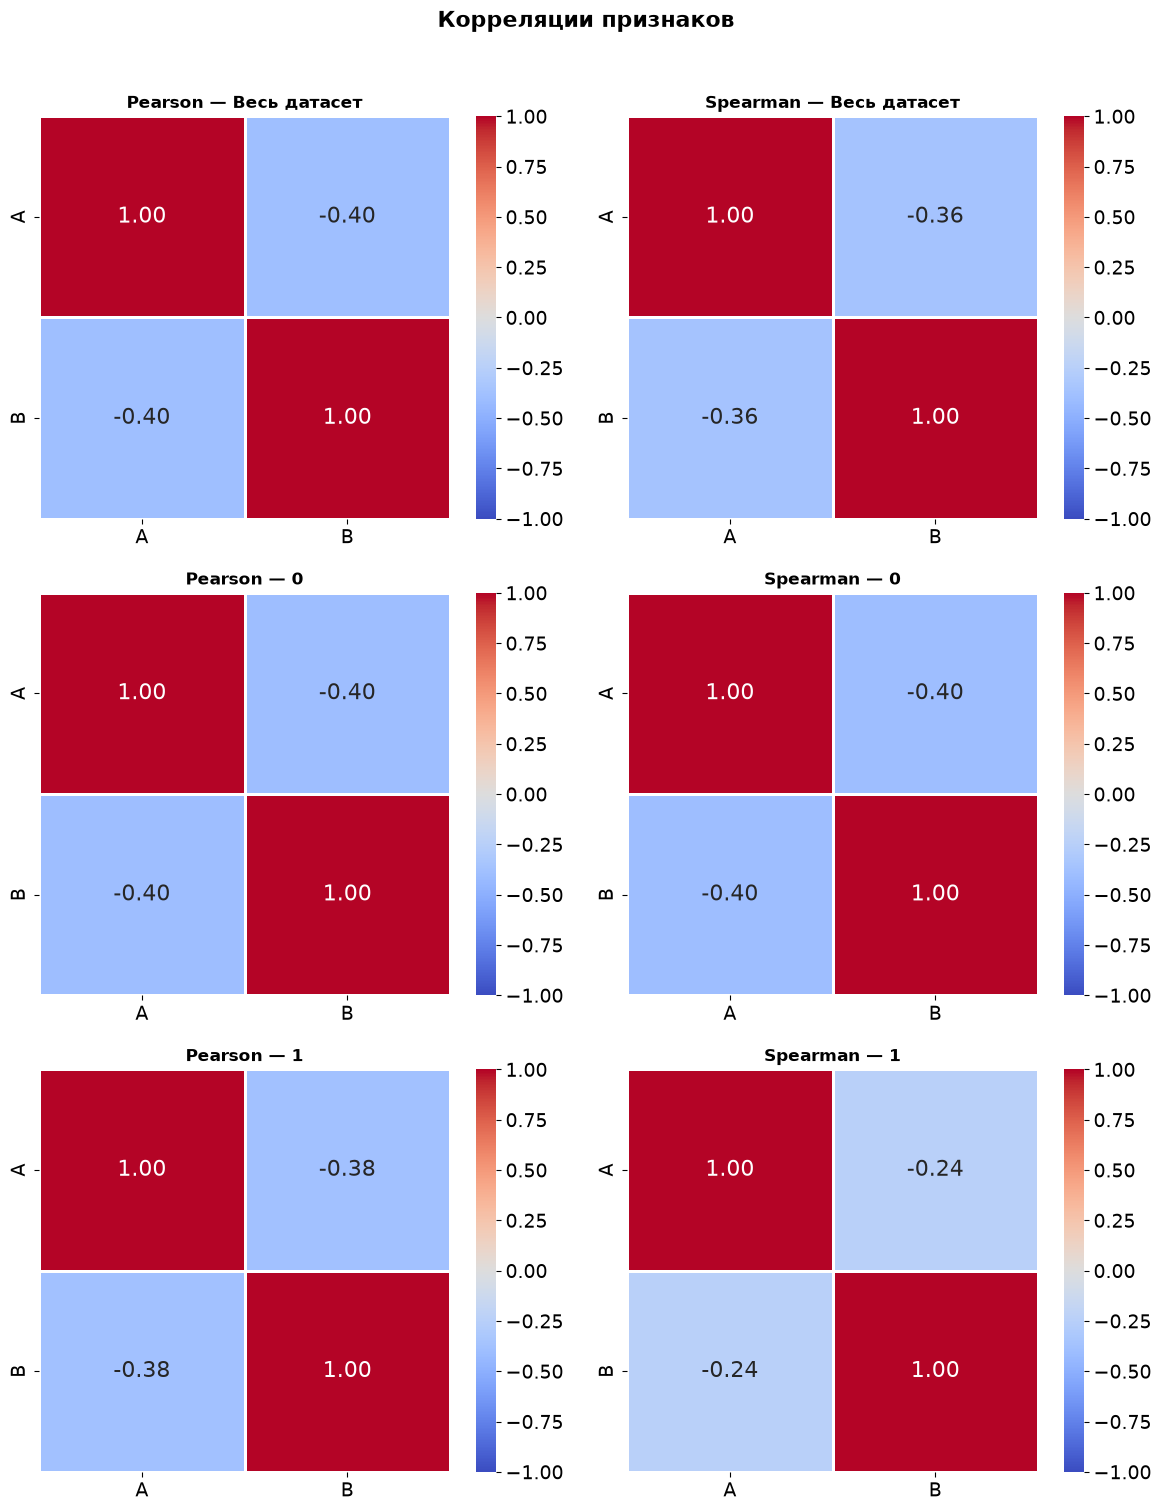

In [96]:
def plot_correlation_heatmaps(df, features):
    groups = [('Весь датасет', df)] + list(df.groupby('class'))

    fig, axes = plt.subplots(len(groups), 2, figsize=(12, 5 * len(groups)))
    axes = np.atleast_2d(axes)

    for i, (name, data) in enumerate(groups):
        for j, method in enumerate(['pearson', 'spearman']):
            corr = data[features].corr(method=method)
            sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0,
                        fmt='.2f', linewidths=1, linecolor='white', ax=axes[i, j])
            axes[i, j].set_title(f'{method.capitalize()} — {name}', fontsize=12, fontweight='bold')

    fig.suptitle('Корреляции признаков', fontsize=16, fontweight='bold', y=1.01)
    
    plt.tight_layout()
    plt.show()

plot_correlation_heatmaps(dfG, features=['A', 'B'])



Класс 0 | n = 24
Регрессия: y = -0.2169·x + -2.0054
r = -0.4018 | R² = 0.1614
Уровень доверия: 95% | линия: вкл, CI: вкл, PI: вкл


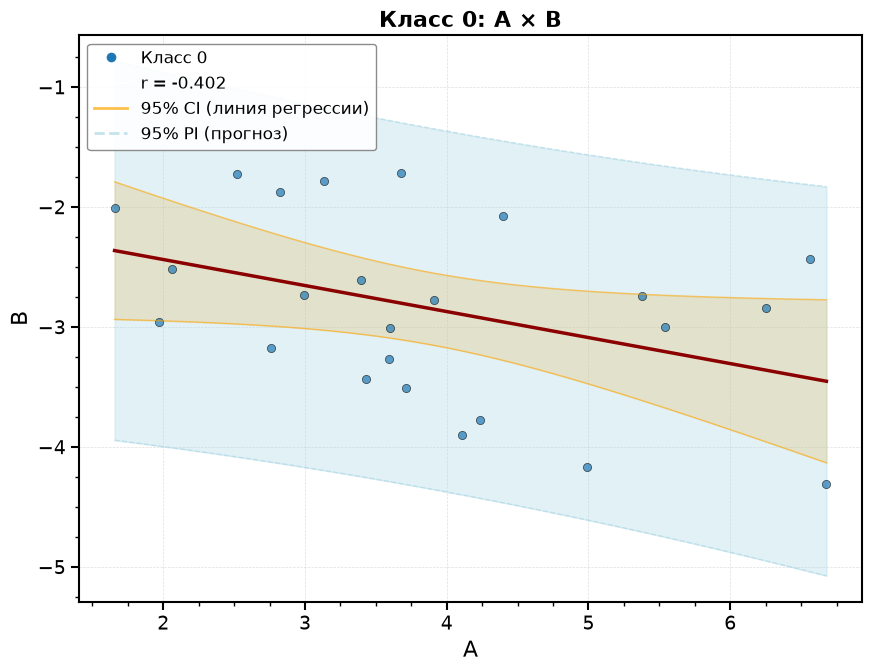

In [103]:
fig, ax = single_class_scatter(
    dfG,
    class_col='class',
    selected_class=0,
    x_feature='A',
    y_feature='B',

    show_regression=SHOW_REGRESSION,
    show_confidence_band=SHOW_CONFIDENCE_BAND,
    show_prediction_band=SHOW_PREDICTION_BAND,
    confidence_level=CONFIDENCE_LEVEL,

    fig_size=(9, 7),
    print_stats=True,

    # --- Регулируемые параметры визуализации (любые из custom_scatter) ---
    point_size=35,
    point_alpha=0.7,
    point_marker="o",
    point_colors="#1f77b4",          # один цвет для одного класса
    point_edgecolor="black",
    point_linewidth=0.5,

    correlation_color="darkred",     # линия регрессии
    correlation_width=2.5,

    confidence_band_color="orange",  # полоса CI
    confidence_band_alpha=0.25,
    confidence_band_linestyle="-",
    confidence_band_linewidth=1,

    interval_color="lightblue",      # полоса PI
    interval_alpha=0.35,
    interval_linestyle="--",
    interval_linewidth=1,

    show_grid=True,
    grid_alpha=0.25,
    show_legend=True,
    legend_loc="upper left",
    show_intervals=True,             # текст Δx на графике
)
plt.show()

Класс 1 | n = 25
Регрессия: y = -0.1793·x + -1.8219
r = -0.3780 | R² = 0.1429
Уровень доверия: 95% | линия: вкл, CI: вкл, PI: вкл


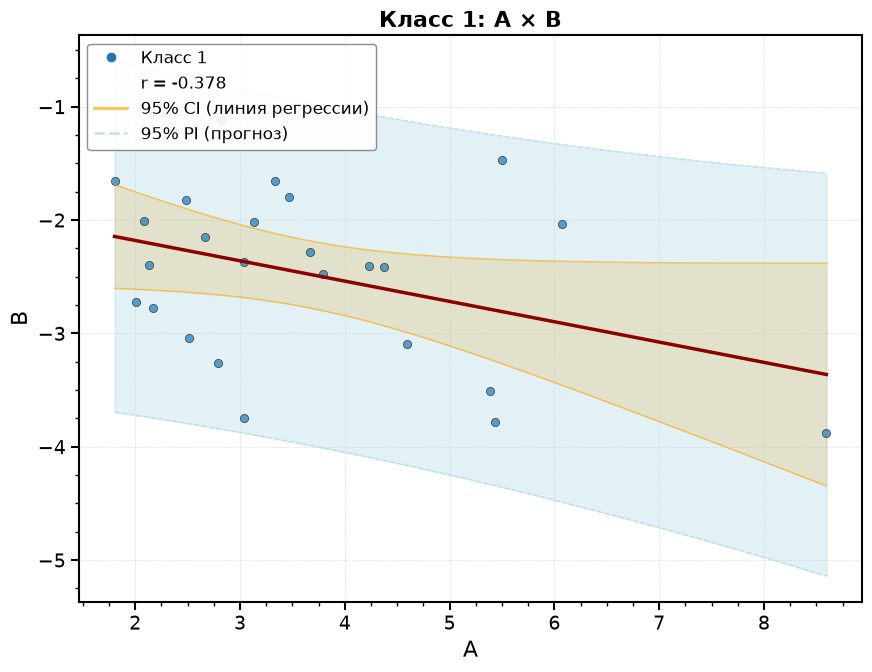

In [104]:
fig, ax = single_class_scatter(
    dfG,
    class_col='class',
    selected_class=1,
    x_feature='A',
    y_feature='B',

    show_regression=SHOW_REGRESSION,
    show_confidence_band=SHOW_CONFIDENCE_BAND,
    show_prediction_band=SHOW_PREDICTION_BAND,
    confidence_level=CONFIDENCE_LEVEL,

    fig_size=(9, 7),
    print_stats=True,

    # --- Регулируемые параметры визуализации (любые из custom_scatter) ---
    point_size=35,
    point_alpha=0.7,
    point_marker="o",
    point_colors="#1f77b4",          # один цвет для одного класса
    point_edgecolor="black",
    point_linewidth=0.5,

    correlation_color="darkred",     # линия регрессии
    correlation_width=2.5,

    confidence_band_color="orange",  # полоса CI
    confidence_band_alpha=0.25,
    confidence_band_linestyle="-",
    confidence_band_linewidth=1,

    interval_color="lightblue",      # полоса PI
    interval_alpha=0.35,
    interval_linestyle="--",
    interval_linewidth=1,

    show_grid=True,
    grid_alpha=0.25,
    show_legend=True,
    legend_loc="upper left",
    show_intervals=True,             # текст Δx на графике
)
plt.show()